# 전쟁은 경제를 몇 년 전으로 되돌리나? — 개발도상국 분쟁 충격과 회복 분석
**남서울대학교 임동하** (Part 1의 Model 1 구조 예측 MLP는 팀 프로젝트 당시 홍태겸 작성)

| 파트 | 질문 | 방법 |
|---|---|---|
| Part 1. 데이터 구축 | 개도국 국가×연도 패널 | World Bank WDI API + EM-DAT 자연재해 + 전투사망(VC.BTL.DETH) |
| Part 2. 기존 팀 분석 | 충격이 다음 해 경제구조를 바꾸나 / 회복력 회귀 | MLP 회귀, 반사실 시나리오 |
| Part 3. 회복 실패 예측 | 충격 3년 뒤 1인당 GDP가 충격 직전보다 낮은 나라를 미리 고를 수 있나 | 로지스틱 vs MLP, 국가 단위 교차검증, 단순 규칙과 비교 |
| Part 4. 후퇴 연수 | 분쟁은 1인당 GDP를 몇 년 전 수준으로 되돌리나 (우크라이나 2022) | 관측 기반 계산 (모델 예측 아님) |
| Part 5. 강건성 검증 | 결론이 분석 선택에 따라 뒤집히나 | 기준 변경, 국가 단위 부트스트랩, MLP 재설정 |

**미리 정한 가설과 판정 기준** — H1: 구조 변수 모델이 "올해 성장률만 보는 단순 규칙"보다 AUC가 높다. H2: 완충 변수(송금·원조·인플레이션·군사비)를 추가하면 AUC가 오른다.

※ 실행: Colab Secrets에 `KAGGLE_API_TOKEN` 등록 후 런타임 → 모두 실행. 기존 노트북의 스케일링 누락 버그 셀(평시/전쟁 재예측)은 제거함.

# Part 1. 데이터 구축

#분석 환경 및 API 인증 구성

In [ ]:
# Colab Secrets에 저장한 토큰을 환경변수로 불러옴

from google.colab import userdata
import os
os.environ['KAGGLE_API_TOKEN'] = userdata.get('KAGGLE_API_TOKEN')

#원천 데이터 수집 (WDI·EM-DAT)

In [ ]:

# WDI: 소비·생산 구조의 기본 베이스 / EM-DAT: 재해 충격 변수의 출처
!kaggle datasets download -d utkarshx27/world-development-indicators-dataset
!kaggle datasets download -d mexwell/natural-disasters-emergency-events-database

# zip 압축 해제
!unzip -o world-development-indicators-dataset.zip -d wdi
!unzip -o natural-disasters-emergency-events-database.zip -d emdat

Dataset URL: https://www.kaggle.com/datasets/utkarshx27/world-development-indicators-dataset
License(s): world-bank
world-development-indicators-dataset.zip: Skipping, found more recently modified local copy (use --force to force download)
Dataset URL: https://www.kaggle.com/datasets/mexwell/natural-disasters-emergency-events-database
License(s): other
natural-disasters-emergency-events-database.zip: Skipping, found more recently modified local copy (use --force to force download)
Archive:  world-development-indicators-dataset.zip
  inflating: wdi/9d2b4a2a-0613-4c51-b5ee-7ed6d467187a_Data.csv  
  inflating: wdi/9d2b4a2a-0613-4c51-b5ee-7ed6d467187a_Series - Metadata.csv  
Archive:  natural-disasters-emergency-events-database.zip
  inflating: emdat/_EmergencyEventsDatabase-CountryProfiles_emdat-country-profiles_2023_04_06.csv  


#수집 파일 구조 확인

In [ ]:
import os

for folder in ['wdi', 'emdat']:
    print(f"── {folder} ──")
    for name in os.listdir(folder):
        print("  ", name)

── wdi ──
   9d2b4a2a-0613-4c51-b5ee-7ed6d467187a_Data.csv
   9d2b4a2a-0613-4c51-b5ee-7ed6d467187a_Series - Metadata.csv
── emdat ──
   _EmergencyEventsDatabase-CountryProfiles_emdat-country-profiles_2023_04_06.csv


#원자료 스키마 검증

In [ ]:
import pandas as pd

# WDI 구조 확인
wdi = pd.read_csv('wdi/9d2b4a2a-0613-4c51-b5ee-7ed6d467187a_Data.csv')
print("=== WDI ===")
print("shape:", wdi.shape)
print("columns:", list(wdi.columns))
print(wdi.head(3))

# EM-DAT는 파싱 실패 → 표로 읽지 말고 raw 텍스트로 앞 25줄 직접 확인
# repr()로 출력해 구분자·따옴표·빈칸까지 그대로 보이게 함
print("\n=== EM-DAT raw (앞 25줄) ===")
path = 'emdat/_EmergencyEventsDatabase-CountryProfiles_emdat-country-profiles_2023_04_06.csv'
with open(path, encoding='latin-1') as f:
    for i, line in enumerate(f):
        print(i, repr(line))
        if i >= 24:
            break

=== WDI ===
shape: (1483, 20)
columns: ['Country Name', 'Country Code', 'Series Name', 'Series Code', '2000 [YR2000]', '2001 [YR2001]', '2002 [YR2002]', '2003 [YR2003]', '2004 [YR2004]', '2005 [YR2005]', '2006 [YR2006]', '2014 [YR2014]', '2015 [YR2015]', '2016 [YR2016]', '2017 [YR2017]', '2018 [YR2018]', '2019 [YR2019]', '2020 [YR2020]', '2021 [YR2021]', '2022 [YR2022]']
  Country Name Country Code  \
0        World          WLD   
1        World          WLD   
2        World          WLD   

                                         Series Name        Series Code  \
0  Access to clean fuels and technologies for coo...     EG.CFT.ACCS.ZS   
1  Access to clean fuels and technologies for coo...  EG.CFT.ACCS.RU.ZS   
2  Access to clean fuels and technologies for coo...  EG.CFT.ACCS.UR.ZS   

      2000 [YR2000]     2001 [YR2001]     2002 [YR2002]     2003 [YR2003]  \
0   49.386911202714  49.8015565650654  50.3645029255777  50.8127349472587   
1  24.3523850006051  24.5477056910194  24.6979

#데이터 적재 및 변수 가용성 점검

In [ ]:
import pandas as pd

# EM-DAT: 세미콜론 구분 + 콤마 CSV → sep/decimal 지정해야 제대로 읽힘
emdat = pd.read_csv(
    'emdat/_EmergencyEventsDatabase-CountryProfiles_emdat-country-profiles_2023_04_06.csv',
    sep=';', decimal=',', encoding='latin-1'
)
print("=== EM-DAT ===")
print("shape:", emdat.shape)
print("columns:", list(emdat.columns))
print("연도 범위:", emdat['Year'].min(), "~", emdat['Year'].max())
print(emdat.head(3))

# WDI: 이 파일에 우리가 필요한 지표가 있는지
wdi = pd.read_csv('wdi/9d2b4a2a-0613-4c51-b5ee-7ed6d467187a_Data.csv')
print("\n=== WDI 지표 목록 ===")
print("지표 수:", wdi['Series Name'].nunique())
for s in sorted(wdi['Series Name'].dropna().unique()):
    print(" -", s)

=== EM-DAT ===
shape: (10431, 13)
columns: ['Year', 'Country', 'ISO', 'Disaster Group', 'Disaster Subroup', 'Disaster Type', 'Disaster Subtype', 'Total Events', 'Total Affected', 'Total Deaths', 'Total Damage (USD, original)', 'Total Damage (USD, adjusted)', 'CPI']
연도 범위: 1900 ~ 2023
   Year     Country  ISO Disaster Group Disaster Subroup Disaster Type  \
0  1900  Cabo Verde  CPV        Natural   Climatological       Drought   
1  1900       India  IND        Natural   Climatological       Drought   
2  1900     Jamaica  JAM        Natural     Hydrological         Flood   

  Disaster Subtype  Total Events  Total Affected  Total Deaths  \
0          Drought             1             NaN       11000.0   
1          Drought             1             NaN     1250000.0   
2              NaN             1             NaN         300.0   

   Total Damage (USD, original)  Total Damage (USD, adjusted)       CPI  
0                           NaN                           NaN  2.849084  
1    

#국가 단위 패널 지표 재수집

In [ ]:
!pip install -q wbgapi
import wbgapi as wb, pandas as pd, requests

# 받은 캐글 WDI는 'World' 집계만 있어 국가별 데이터가 없었음
# → 세계은행 API로 필요한 지표만 '국가별'로 직접 수집
indicators = {
    'NV.AGR.TOTL.ZS': 'agri_pct',       # 농업 부가가치 (% of GDP)
    'NV.IND.TOTL.ZS': 'ind_pct',        # 산업 부가가치 (% of GDP)
    'NV.SRV.TOTL.ZS': 'srv_pct',        # 서비스 부가가치 (% of GDP)
    'NE.CON.PRVT.ZS': 'hh_cons_pct',    # 가계 최종소비 (% of GDP)
    'NE.CON.GOVT.ZS': 'gov_cons_pct',   # 정부 최종소비 (% of GDP)
    'NE.GDI.TOTL.ZS': 'gcf_pct',        # 총자본형성(투자) (% of GDP)
    'NE.EXP.GNFS.ZS': 'exp_pct',        # 수출 (% of GDP)
    'NE.IMP.GNFS.ZS': 'imp_pct',        # 수입 (% of GDP)
    'SP.POP.TOTL':    'pop',            # 총인구
    'NY.GDP.MKTP.KD.ZG': 'gdp_growth',  # GDP 성장률 (연 %)
}

# 국가×연도 = 행, 지표 = 컬럼으로 받기
wdi_panel = wb.data.DataFrame(list(indicators.keys()),
                              economy='all', time=range(2000, 2023),
                              columns='series', skipBlanks=False).reset_index()
wdi_panel = wdi_panel.rename(columns={'economy': 'Country Code', 'time': 'year_raw', **indicators})
wdi_panel['year'] = wdi_panel['year_raw'].astype(str).str.extract(r'(\d{4})').astype(int)
wdi_panel = wdi_panel.drop(columns=['year_raw'])

print("WDI(API) shape:", wdi_panel.shape)
print("국가/지역 수:", wdi_panel['Country Code'].nunique())
wdi_panel.head() # 앞 5국가만 선별

WDI(API) shape: (6118, 12)
국가/지역 수: 266


,Country Code,gov_cons_pct,hh_cons_pct,exp_pct,gcf_pct,imp_pct,agri_pct,ind_pct,srv_pct,gdp_growth,pop,year
0,ABW,21.419540,49.387204,74.386011,25.494114,70.686869,0.018608,13.175955,79.089632,7.622921,90588.0,2000
1,ABW,24.841972,49.556391,70.996784,23.999178,69.394325,0.018617,13.054069,79.322247,4.182002,91439.0,2001
2,ABW,24.890224,52.581940,64.564314,26.629980,68.666458,0.018054,13.241621,79.375260,-0.944953,92074.0,2002
3,ABW,24.444651,54.005510,62.731213,28.881704,70.063078,0.018011,14.892210,77.409073,1.110505,93128.0,2003
4,ABW,22.886679,51.761742,64.665559,28.451392,67.765371,0.017566,15.596508,76.456581,7.293728,95138.0,2004


#분석 대상 표본 정의 및 데이터 통합

In [ ]:
# 개발도상국 필터 (세계은행 소득그룹: 고소득국·집계지역 제외)
meta = requests.get('https://api.worldbank.org/v2/country?format=json&per_page=400').json()[1]
classif = pd.DataFrame([{'iso3': c['id'], 'income': c['incomeLevel']['value'],
                         'region': c['region']['value']} for c in meta])
developing = set(classif[(classif['region'] != 'Aggregates') &
                         (classif['income'] != 'High income')]['iso3'])
wdi_panel = wdi_panel[wdi_panel['Country Code'].isin(developing)].copy()
print("개도국 필터 후:", wdi_panel.shape, "| 국가 수:", wdi_panel['Country Code'].nunique())

# EM-DAT 자연재해 → 국가×연도 집계
nat = emdat[emdat['Disaster Group'] == 'Natural'].copy()
emdat_year = nat.groupby(['ISO', 'Year']).agg(
    dis_events=('Total Events', 'sum'),   dis_deaths=('Total Deaths', 'sum'),
    dis_affected=('Total Affected', 'sum'), dis_damage=('Total Damage (USD, adjusted)', 'sum'),
).reset_index()
emdat_year['disaster_flag'] = 1
emdat_year = emdat_year.rename(columns={'ISO': 'Country Code', 'Year': 'year'})

# WDI 기준 left 병합 → 재해 없던 해는 0
panel = wdi_panel.merge(emdat_year, on=['Country Code', 'year'], how='left')
dis_cols = ['dis_events','dis_deaths','dis_affected','dis_damage','disaster_flag']
panel[dis_cols] = panel[dis_cols].fillna(0)

print("최종 패널 shape:", panel.shape)
print("재해 있던 국가-연도 비율:", round(panel['disaster_flag'].mean(), 3))
# 한 국가만 전체 연도 보기 (예: 아프가니스탄)
panel[panel['Country Code'] == 'AFG']

개도국 필터 후: (3013, 12) | 국가 수: 131
최종 패널 shape: (3013, 17)
재해 있던 국가-연도 비율: 0.624


,Country Code,gov_cons_pct,hh_cons_pct,exp_pct,gcf_pct,imp_pct,agri_pct,ind_pct,srv_pct,gdp_growth,pop,year,dis_events,dis_deaths,dis_affected,dis_damage,disaster_flag
0,AFG,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,20130327.0,2000,1.0,37.0,2580000.0,84975.0,1.0
1,AFG,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-9.431974,20284307.0,2001,4.0,331.0,200270.0,16528.0,1.0
2,AFG,NaN,NaN,NaN,NaN,NaN,38.627892,23.810127,36.151155,28.600001,21378117.0,2002,8.0,1286.0,106836.0,0.0,1.0
3,AFG,NaN,NaN,NaN,NaN,NaN,37.418855,22.710864,37.444804,8.832278,22733049.0,2003,9.0,137.0,4754.0,0.0,1.0
4,AFG,NaN,NaN,NaN,NaN,NaN,29.721067,26.226790,41.110895,1.414118,23560654.0,2004,3.0,18.0,5540.0,0.0,1.0
5,AFG,NaN,NaN,NaN,NaN,NaN,31.114855,26.812099,39.007787,11.229715,24404567.0,2005,12.0,570.0,41475.0,7567691.0,1.0
6,AFG,NaN,NaN,NaN,NaN,NaN,28.635969,28.210768,39.831024,5.357403,25424094.0,2006,13.0,382.0,2233910.0,0.0,1.0
7,AFG,NaN,NaN,NaN,NaN,NaN,30.105011,26.882242,40.294685,13.826320,25909852.0,2007,7.0,296.0,30255.0,0.0,1.0
8,AFG,NaN,NaN,NaN,NaN,NaN,24.892270,26.915628,45.409831,3.924984,26482622.0,2008,3.0,1317.0,451864.0,0.0,1.0
9,AFG,NaN,NaN,NaN,NaN,NaN,29.297501,21.897122,45.244435,21.390528,27466101.0,2009,5.0,101.0,65857.0,27282458.0,1.0


#결측 구조 진단

In [ ]:
# 결측치 점검 — 모델로 가기 전 필수 단계
print("컬럼별 결측 비율:")
print(panel.isna().mean().round(3).sort_values(ascending=False))

# 핵심 변수(생산 3 + 소비 3 + 성장률)가 모두 채워진 행이 얼마나 남나
core = ['agri_pct','ind_pct','srv_pct','hh_cons_pct','gov_cons_pct','gcf_pct','gdp_growth']
complete = panel.dropna(subset=core)
print("\n핵심변수 완전한 행:", complete.shape[0], "/ 전체", panel.shape[0],
      "| 국가 수:", complete['Country Code'].nunique())

컬럼별 결측 비율:
gcf_pct          0.186
hh_cons_pct      0.185
gov_cons_pct     0.182
imp_pct          0.158
exp_pct          0.158
srv_pct          0.074
ind_pct          0.060
agri_pct         0.056
gdp_growth       0.026
Country Code     0.000
pop              0.000
year             0.000
dis_events       0.000
dis_deaths       0.000
dis_affected     0.000
dis_damage       0.000
disaster_flag    0.000
dtype: float64

핵심변수 완전한 행: 2329 / 전체 3013 | 국가 수: 114


# 충격–구조 변화 간 예비 분석

재해 강도 구간별 |Δ구조| 평균 (%p):
          d_agri_pct  d_ind_pct  d_srv_pct  d_hh_cons_pct  d_gov_cons_pct  \
sev                                                                         
0_none         1.024      2.069      2.047          3.330           1.670   
1_mild         0.927      1.475      1.507          2.611           1.239   
2_severe       0.945      1.306      1.283          2.188           0.829   

          d_gcf_pct  
sev                  
0_none        3.475  
1_mild        2.717  
2_severe      2.373  


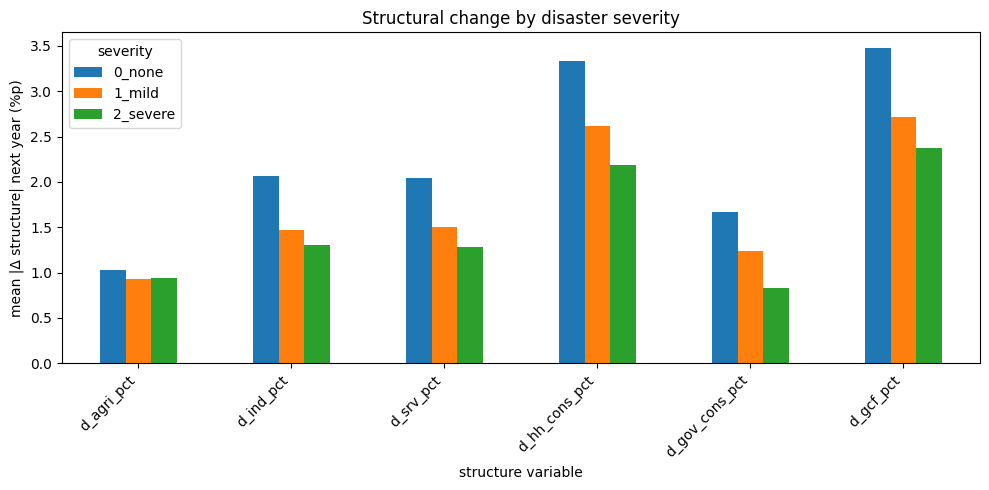

In [ ]:
import numpy as np, matplotlib.pyplot as plt

core   = ['agri_pct','ind_pct','srv_pct','hh_cons_pct','gov_cons_pct','gcf_pct','gdp_growth']
struct = ['agri_pct','ind_pct','srv_pct','hh_cons_pct','gov_cons_pct','gcf_pct']

# 결측 행 제거 + 국가·연도 순 정렬
df = panel.dropna(subset=core).sort_values(['Country Code','year']).copy()

# 국가 내에서 '다음해 구조 - 올해 구조' = 우리가 예측할 변화량(Δ)
df['next_year'] = df.groupby('Country Code')['year'].shift(-1)
for c in struct:
    df[f'd_{c}'] = df.groupby('Country Code')[c].shift(-1) - df[c]
df = df[(df['next_year'] - df['year']) == 1].copy()   # 연속된 해 쌍만 사용

# 재해 강도 3구간: 없음 / 약함 / 강함 (재해 발생 해의 사망자 중앙값 기준)
med = df.loc[df['disaster_flag'] == 1, 'dis_deaths'].median()
def tier(r):
    if r['disaster_flag'] == 0: return '0_none'
    return '2_severe' if r['dis_deaths'] >= med else '1_mild'
df['sev'] = df.apply(tier, axis=1)

# 구간별 '구조 변화량 절댓값' 평균 → 충격이 클수록 구조가 더 크게 움직이는지 확인
dcols = [f'd_{c}' for c in struct]
absd = df.groupby('sev')[dcols].apply(lambda g: g.abs().mean()).sort_index()
print("재해 강도 구간별 |Δ구조| 평균 (%p):")
print(absd.round(3))

absd.T.plot(kind='bar', figsize=(10,5))
plt.ylabel('mean |Δ structure| next year (%p)')
plt.xlabel('structure variable'); plt.title('Structural change by disaster severity')
plt.legend(title='severity'); plt.xticks(rotation=45, ha='right')
plt.tight_layout(); plt.show()

In [ ]:
import numpy as np

# 절대 사망자 수는 국가 규모와 혼동됨 → '인구 100만명당 사망자'로 정규화
df['deaths_pm'] = df['dis_deaths'] / df['pop'] * 1e6

# 강함 = 인구대비 사망이 전체 상위 10%인 해 (0이 많아 중앙값 대신 분위수 사용)
thr = df['deaths_pm'].quantile(0.90)
df['sev2'] = np.where(df['disaster_flag'] == 0, '0_none',
              np.where(df['deaths_pm'] >= thr, '2_severe', '1_mild'))
print("구간별 표본 수:\n", df['sev2'].value_counts(), "\n")

absd2 = df.groupby('sev2')[dcols].apply(lambda g: g.abs().mean()).sort_index()
print("인구대비 재해강도 구간별 |Δ구조| 평균 (%p):")
print(absd2.round(3))

구간별 표본 수:
 sev2
1_mild      1254
0_none       738
2_severe     222
Name: count, dtype: int64 

인구대비 재해강도 구간별 |Δ구조| 평균 (%p):
          d_agri_pct  d_ind_pct  d_srv_pct  d_hh_cons_pct  d_gov_cons_pct  \
sev2                                                                        
0_none         1.024      2.069      2.047          3.330           1.670   
1_mild         0.931      1.442      1.419          2.361           1.074   
2_severe       0.962      1.096      1.260          2.613           0.801   

          d_gcf_pct  
sev2                 
0_none        3.475  
1_mild        2.430  
2_severe      3.191  


In [ ]:
# 재해 강도 구간별 '당해 GDP 성장률' 비교
print("재해강도 구간별 GDP 성장률:")
print(df.groupby('sev2')['gdp_growth'].agg(['mean','median','count']).round(2))

재해강도 구간별 GDP 성장률:
          mean  median  count
sev2                         
0_none    4.01    4.16    738
1_mild    4.09    4.41   1254
2_severe  3.53    3.85    222


# 분쟁 변수 결합 및 신호 교차 검증

In [ ]:
import wbgapi as wb, numpy as np

# 'battle' 관련 WDI 지표 코드를 직접 검색 (코드 추측 대신)
cands = list(wb.series.list(q='battle'))
print("검색된 지표:", [(c['id'], c['value']) for c in cands])
code = cands[0]['id']            # 보통 'Battle-related deaths' 하나만 잡힘
print("사용 코드:", code, "\n")

# 전쟁 강도 받아서 df에 병합 (재실행 대비 기존 컬럼 제거 후 병합)
war = wb.data.DataFrame(code, economy='all', time=range(2000,2023),
                        columns='series', skipBlanks=False).reset_index()
war = war.rename(columns={'economy':'Country Code','time':'year_raw', code:'battle_deaths'})
war['year'] = war['year_raw'].astype(str).str.extract(r'(\d{4})').astype(int)

df = df.drop(columns=['battle_deaths','war_flag'], errors='ignore')
df = df.merge(war[['Country Code','year','battle_deaths']], on=['Country Code','year'], how='left')
df['battle_deaths'] = df['battle_deaths'].fillna(0)   # 결측 = 분쟁 없음
df['war_flag'] = (df['battle_deaths'] > 0).astype(int)

print("전쟁(전투사망>0) 국가-연도 비율:", round(df['war_flag'].mean(),3),
      "| 전쟁 행 수:", int(df['war_flag'].sum()))
print("\n전쟁 vs 평시 — 다음해 |Δ구조| 평균 (%p):")
print(df.groupby('war_flag')[dcols].apply(lambda g: g.abs().mean()).round(3))
print("\n전쟁 vs 평시 — GDP 성장률:")
print(df.groupby('war_flag')['gdp_growth'].agg(['mean','median','count']).round(2))

검색된 지표: [('VC.BTL.DETH', 'Battle-related deaths (number of people)')]
사용 코드: VC.BTL.DETH 

전쟁(전투사망>0) 국가-연도 비율: 0.215 | 전쟁 행 수: 476

전쟁 vs 평시 — 다음해 |Δ구조| 평균 (%p):
          d_agri_pct  d_ind_pct  d_srv_pct  d_hh_cons_pct  d_gov_cons_pct  \
war_flag                                                                    
0              0.927      1.468      1.483          2.685           1.251   
1              1.106      2.158      2.084          2.796           1.224   

          d_gcf_pct  
war_flag             
0             2.909  
1             2.657  

전쟁 vs 평시 — GDP 성장률:
          mean  median  count
war_flag                     
0         4.10    4.26   1738
1         3.67    4.36    476


# 학습용 특징·타깃 설계

In [ ]:
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# 전체 병합본(panel)에 전쟁 변수 결합
m = panel.merge(war[['Country Code','year','battle_deaths']], on=['Country Code','year'], how='left')
m['battle_deaths'] = m['battle_deaths'].fillna(0)

# 특징·타깃에 쓸 핵심 변수 결측 행 제거 + 정렬
core = ['agri_pct','ind_pct','srv_pct','hh_cons_pct','gov_cons_pct','gcf_pct',
        'exp_pct','imp_pct','gdp_growth']
m = m.dropna(subset=core).sort_values(['Country Code','year']).copy()

# 충격·맥락 변수 가공 (인구 대비 + 로그로 분포 안정화)
m['war_flag']    = (m['battle_deaths'] > 0).astype(int)
m['log_bdeaths'] = np.log1p(m['battle_deaths'] / m['pop'] * 1e6)   # 인구100만당 전투사망(log)
m['log_ddeaths'] = np.log1p(m['dis_deaths']   / m['pop'] * 1e6)   # 인구100만당 재해사망(log)
m['log_pop']     = np.log1p(m['pop'])

# 타깃 Y: '다음 해' 구조 6개 (국가 내에서 한 칸 당김)
struct = ['agri_pct','ind_pct','srv_pct','hh_cons_pct','gov_cons_pct','gcf_pct']
m['next_year'] = m.groupby('Country Code')['year'].shift(-1)
for c in struct:
    m[f'y_{c}'] = m.groupby('Country Code')[c].shift(-1)

# 연속된 해 쌍 + 타깃 결측 없는 행만 사용
target_cols = [f'y_{c}' for c in struct]
m = m[(m['next_year'] - m['year'] == 1)].dropna(subset=target_cols).copy()

# 입력 X = 현재 구조 + 무역 + 맥락 + 충격 / 출력 Y = 다음 해 구조 6개
feat = struct + ['exp_pct','imp_pct','log_pop','gdp_growth',
                 'war_flag','log_bdeaths','disaster_flag','log_ddeaths']
X, Y = m[feat].values, m[target_cols].values
print("학습 데이터:", X.shape, "→", Y.shape, "| 국가 수:", m['Country Code'].nunique())

# 8:2 분할 (우선 단순 랜덤) + 입력 스케일링(train 기준 fit → 누수 방지)
X_tr, X_te, Y_tr, Y_te = train_test_split(X, Y, test_size=0.2, random_state=42)
scaler = StandardScaler().fit(X_tr)
X_tr, X_te = scaler.transform(X_tr), scaler.transform(X_te)
print("train:", X_tr.shape, "| test:", X_te.shape)

학습 데이터: (2214, 14) → (2214, 6) | 국가 수: 114
train: (1771, 14) | test: (443, 14)


# Part 2. 기존 팀 분석 (Model 1: 다음 해 경제구조 예측 MLP / Model 2: 회복력 회귀)

# 예측 모델 아키텍처 설계

In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

# MLP(다층 퍼셉트론) 모델 생성
# 현재 국가의 경제 구조와 무역, 인구,
# 성장률, 전쟁 및 재난 정보를 입력받아
# 다음 해 생산·소비 구조 6개를 예측하는 모델

model = Sequential([

    # 첫 번째 은닉층
    # 입력 변수들 간의 비선형 관계를 학습
    # 64개의 노드를 사용하여 주요 특징 추출
    Dense(
        64,
        activation='relu',
        input_shape=(X_tr.shape[1],)
    ),

    # 과적합 방지
    # 학습 과정에서 일부 노드를 무작위 제외
    Dropout(0.2),

    # 두 번째 은닉층
    # 경제구조 변화 패턴을 추가로 학습
    # 첫 번째 은닉층에서 추출된 특징을 재가공
    Dense(
        32,
        activation='relu'
    ),

    # 추가적인 과적합 방지
    Dropout(0.2),

    # 출력층
    # 다음 해 경제구조 변수 6개를 예측
    # 회귀 문제이므로 활성화 함수 사용 안 함
    Dense(Y_tr.shape[1])
])

# 모델 학습 설정
#
# optimizer : Adam
# → 학습 속도가 빠르고 안정적인 경사하강법
#
# loss : MSE
# → 실제값과 예측값의 오차를 제곱하여 계산
#
# metrics : MAE
# → 예측값이 실제값과 평균적으로 얼마나 차이나는지 확인

model.compile(
    optimizer='adam',
    loss='mse',
    metrics=['mae']
)

# 모델 구조 확인
# 각 층의 노드 수와 파라미터 수 출력
model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │           960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 6)              │           198 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,238 (12.65 KB)

 Trainable params: 3,238 (12.65 KB)

 Non-trainable params: 0 (0.00 B)

# 모델 학습 및 조기 종료

In [ ]:
# Early Stopping 적용
# 검증 데이터의 손실(val_loss)이
# 일정 기간 동안 개선되지 않으면
# 학습을 자동으로 종료한다.
# 불필요한 학습을 줄이고
# 과적합(Overfitting)을 방지하기 위해 사용

early_stop = EarlyStopping(

    # 검증 손실 기준으로 성능 확인
    monitor='val_loss',

    # 30 epoch 동안 성능 개선이 없으면 종료
    # 데이터 규모가 비교적 크고
    # 손실 감소가 천천히 진행될 수 있어
    # 충분한 학습 기회를 주기 위해 30으로 설정 (성능 향상을 위해)
    #(5,10 은 epoch가 val_loss가 줄고 있는 와중에 종료됌)
    patience=30,

    # 가장 성능이 좋았던 시점의 가중치 복원
    restore_best_weights=True

)

# 모델 학습 수행
# X_tr : 입력 데이터
# Y_tr : 정답 데이터
# train 데이터의 20%를 검증용으로 사용하여
# 학습 중 모델 성능을 지속적으로 확인

history = model.fit(

    X_tr,
    Y_tr,

    # 검증 데이터 비율
    validation_split=0.2,

    # 최대 학습 횟수
    # 실제 학습은 Early Stopping에 의해
    # 더 일찍 종료될 수 있음
    epochs=1000,

    # 한 번에 32개 데이터씩 학습
    # 메모리 사용량과 학습 안정성을 고려
    batch_size=32,

    # 조기 종료 적용
    callbacks=[early_stop],

    # 학습 과정 출력
    verbose=1

)

Epoch 1/1000
45/45 ━━━━━━━━━━━━━━━━━━━━ 2s 15ms/step - loss: 1603.0802 - mae: 32.9958 - val_loss: 1482.4465 - val_mae: 31.8637
Epoch 2/1000
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 1362.3707 - mae: 29.8510 - val_loss: 1086.3092 - val_mae: 26.1495
Epoch 3/1000
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 799.5919 - mae: 21.3458 - val_loss: 474.3009 - val_mae: 16.1102
Epoch 4/1000
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 368.5863 - mae: 14.0691 - val_loss: 228.8073 - val_mae: 11.2093
Epoch 5/1000
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 243.0428 - mae: 11.4807 - val_loss: 159.3445 - val_mae: 9.4118
Epoch 6/1000
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 200.3607 - mae: 10.4166 - val_loss: 132.3174 - val_mae: 8.5440
Epoch 7/1000
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 174.8999 - mae: 9.7932 - val_loss: 114.2984 - val_mae: 7.9213
Epoch 8/1000
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 167.5463 - mae: 9.5182 - val_loss: 104.3898 - val_mae: 7.5287
Epoch 9/1

# 모델 성능 평가

In [ ]:
# 테스트 데이터 성능 평가
loss, mae = model.evaluate(
    X_te,
    Y_te
)

print("Test Loss:", round(loss,4))
print("Test MAE :", round(mae,4))

# Loss(MSE)가 낮을수록 좋음
# MAE가 낮을수록 실제값과 예측값 차이가 작음

14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 14.0170 - mae: 2.4904 
Test Loss: 14.017
Test MAE : 2.4904


# 하이퍼파라미터 탐색

In [ ]:
from tensorflow.keras.optimizers import Adam

# 은닉층 노드 수(u1, u2)와
# Dropout 비율을 변경하면서
# 모델 성능을 비교하기 위한 함수
def build_and_eval(
    u1,
    u2,
    dropout,
    lr=0.001,
    epochs=300
):
    # MLP 모델 생성
    # 다양한 구조를 실험할 수 있도록
    # 은닉층 크기를 함수 입력으로 설정
    m_ = Sequential([
        # 첫 번째 은닉층
        Dense(
            u1,
            activation='relu',
            input_shape=(X_tr.shape[1],)
        ),
        # 과적합 방지
        Dropout(dropout),
        # 두 번째 은닉층
        Dense(
            u2,
            activation='relu'
        ),
        # 과적합 방지
        Dropout(dropout),
        # 출력층
        # 다음 해 경제구조 6개 예측
        Dense(Y_tr.shape[1])
    ])
    # 모델 학습 설정
    # Adam Optimizer 사용
    # 학습률(learning rate)도 실험 가능하도록 변수화
    m_.compile(
        optimizer=Adam(learning_rate=lr),
        loss='mse',
        metrics=['mae']
    )
    # 검증 손실 기준 조기 종료
    # 불필요한 학습을 줄이고 과적합 방지
    es = EarlyStopping(
        monitor='val_loss',
        patience=30,
        restore_best_weights=True
    )
    # 모델 학습
    m_.fit(
        X_tr,
        Y_tr,
        validation_split=0.2,
        epochs=epochs,
        batch_size=32,
        callbacks=[es],
        verbose=0
    )
    # 테스트 데이터 성능 평가
    # loss(MSE)와 MAE를 반환
    loss, mae = m_.evaluate(
        X_te,
        Y_te,
        verbose=0
    )
    # 비교가 쉽도록 소수 셋째 자리까지 출력
    return round(loss, 3), round(mae, 3)

# 학습 곡선 진단 및 시각화

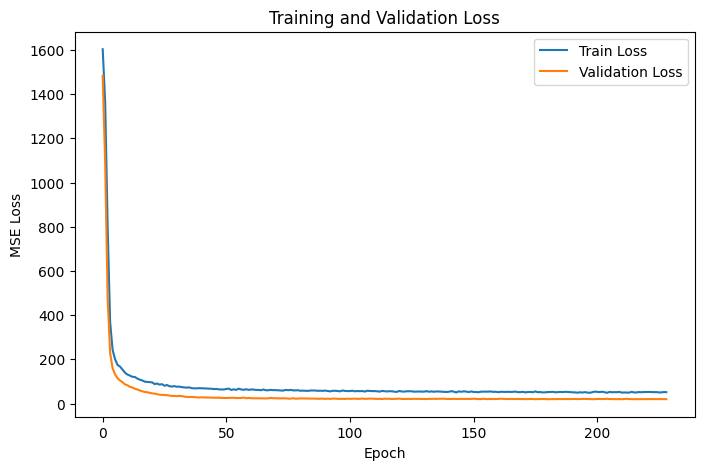

In [ ]:
# 학습 손실곡선 시각화
# train loss : 학습 데이터 오차
# val loss : 검증 데이터 오차

# 두 곡선이 함께 감소하면 정상 학습
# train만 감소하고 val이 증가하면 과적합 발생
plt.figure(figsize=(8, 5))
# 학습 데이터 손실
plt.plot(
    history.history['loss'],
    label='Train Loss'
)
# 검증 데이터 손실
plt.plot(
    history.history['val_loss'],
    label='Validation Loss'
)
# 축 이름 설정
plt.xlabel('Epoch')
plt.ylabel('MSE Loss')
# 그래프 제목
plt.title(
    'Training and Validation Loss'
)
# 범례 표시
plt.legend()
# 그래프 출력
plt.show()

# 변수별 예측 성능 분석

In [ ]:
# 학습이 완료된 모델을 이용하여
# 테스트 데이터의 경제구조를 예측
Y_pred = model.predict(X_te)
# 각 경제구조 변수별 예측 성능 평가
# MAE (Mean Absolute Error)
# → 실제값과 예측값의 평균 절대 오차
# → 값이 작을수록 예측 성능이 우수함
# R² (Coefficient of Determination)
# → 모델이 실제 데이터를 얼마나 설명하는지 나타냄
# → 1에 가까울수록 설명력이 높음
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import r2_score
# 평가 결과 저장용 리스트
result_eval = []
# 생산·소비 구조 변수별 성능 계산
for i, col in enumerate(target_cols):
    # 평균 절대 오차 계산
    mae = mean_absolute_error(
        Y_te[:, i],
        Y_pred[:, i]
    )
    # 결정계수(R²) 계산
    r2 = r2_score(
        Y_te[:, i],
        Y_pred[:, i]
    )
    # 변수명과 성능 지표 저장
    result_eval.append([
        col,
        mae,
        r2
    ])
# 결과를 표 형태로 정리
eval_df = pd.DataFrame(
    result_eval,
    columns=[
        'structure',
        'MAE',
        'R2'
    ]
)
# 경제구조 변수별 성능 출력
print(eval_df)

14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step
        structure       MAE        R2
0      y_agri_pct  1.759877  0.936456
1       y_ind_pct  2.282192  0.911540
2       y_srv_pct  2.281631  0.902278
3   y_hh_cons_pct  3.333980  0.890954
4  y_gov_cons_pct  1.842449  0.932746
5       y_gcf_pct  3.442006  0.719650


# Model 1 검증: naive persistence 기준과 비교 (추가)

In [ ]:
# ================================================================
# Model 1 검증: "올해 구조를 그대로 내년 예측값으로 쓰는" 기준(naive persistence)과 비교
# 다음 해 구조는 올해와 거의 같으므로, R² 0.9가 MLP의 실력인지 확인해야 함
# ================================================================
from sklearn.metrics import mean_absolute_error, r2_score
X_te_raw = scaler.inverse_transform(X_te)[:, :6]          # feat 앞 6개 = 올해 구조
cmp = []
for i, c in enumerate(struct):
    cmp.append([c, mean_absolute_error(Y_te[:, i], Y_pred[:, i]), mean_absolute_error(Y_te[:, i], X_te_raw[:, i]),
                r2_score(Y_te[:, i], Y_pred[:, i]), r2_score(Y_te[:, i], X_te_raw[:, i])])
cmp = pd.DataFrame(cmp, columns=['structure', 'MAE_MLP', 'MAE_naive', 'R2_MLP', 'R2_naive'])
cmp['MLP가 더 나은가'] = cmp['MAE_MLP'] < cmp['MAE_naive']
print(cmp.round(3).to_string(index=False))


   structure  MAE_MLP  MAE_naive  R2_MLP  R2_naive  MLP가 더 나은가
    agri_pct    1.760      0.846   0.936     0.980       False
     ind_pct    2.282      1.381   0.912     0.960       False
     srv_pct    2.282      1.387   0.902     0.953       False
 hh_cons_pct    3.334      2.639   0.891     0.924       False
gov_cons_pct    1.842      1.160   0.933     0.953       False
     gcf_pct    3.442      2.909   0.720     0.750       False


# 예측–실측 적합도 검토

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step
[[15.  22.1 52.9 79.  14.  25.7]
 [ 9.  25.8 52.7 60.4 21.2 19. ]
 [14.9 28.9 45.6 73.2 10.7 20.8]]


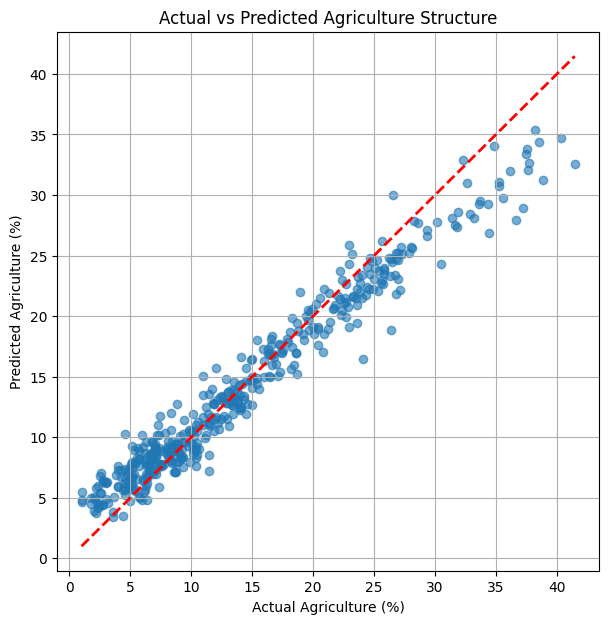

In [ ]:
# 테스트 데이터에 대해 예측을 수행한 후
# 실제값과 예측값의 관계를 산점도로 확인
# 점들이 기준선(y=x)에 가까울수록
# 모델이 실제 경제구조를 정확하게 예측한 것임
plt.figure(figsize=(7, 7))
# 실제값과 예측값 산점도
plt.scatter(
    Y_te[:, 0],
    Y_pred[:, 0],
    alpha=0.6
)
# 이상적인 예측 기준선 생성
# y = x
# → 실제값과 예측값이 완전히 일치하는 경우
min_val = min(
    Y_te[:, 0].min(),
    Y_pred[:, 0].min()
)
max_val = max(
    Y_te[:, 0].max(),
    Y_pred[:, 0].max()
)
plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    'r--',
    linewidth=2
)
# 축 이름 설정
plt.xlabel('Actual Agriculture (%)')
plt.ylabel('Predicted Agriculture (%)')
# 그래프 제목
plt.title(
    'Actual vs Predicted Agriculture Structure'
)
# 시각적 확인을 위한 격자 추가
plt.grid(True)
# 일부 예측 결과 확인
# 예측값이 실제 경제구조 범위(약 20~70%)에
# 위치하는지 점검하여 모델 학습 상태 확인
print(
    model.predict(X_te[:3]).round(1)
)
# 그래프 출력
plt.show()

# 잔차 진단

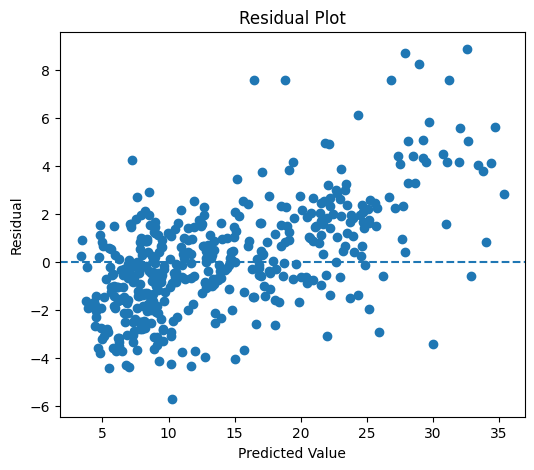

In [ ]:
# 잔차(Residual) 계산
# 잔차 = 실제값 - 예측값
# 잔차를 분석하면 모델이 특정 구간에서
# 과대예측 또는 과소예측하는지 확인할 수 있음
residual = (
    Y_te[:, 0]
    -
    Y_pred[:, 0]
)
plt.figure(figsize=(6, 5))
# 예측값과 잔차의 관계 시각화
plt.scatter(
    Y_pred[:, 0],
    residual
)
# 기준선(y=0)
#
# 잔차가 0이면
# 실제값과 예측값이 완전히 일치
plt.axhline(0,linestyle='--')
# 축 이름 설정
plt.xlabel('Predicted Value')
plt.ylabel('Residual')
# 그래프 제목
plt.title('Residual Plot')
# 그래프 출력
plt.show()

# 반사실 시나리오 분석

In [ ]:
# 분석 대상 국가 선택
# 우간다(UGA)의 가장 최근 데이터를 사용

country = "UGA"
sample = (
    m[m['Country Code'] == country]
    .sort_values('year')
    .iloc[-1]
)
# 모델 입력 데이터 생성
# 현재 국가의 경제 구조와 충격 변수 포함
x_raw = (
    sample[feat]
    .values
    .astype(float)
    .reshape(1, -1)
)
# 전쟁 강도 설정
#
# 실제 전쟁 발생 국가 중
# 상위 10% 수준의 전쟁 강도를 사용
#
# 극단적인 값의 영향을 줄이면서도
# 충분히 큰 충격을 가정하기 위함
severe = (
    m.loc[m['war_flag'] == 1, 'log_bdeaths']
    .quantile(0.9)
)
# ------------------------------------------
# 평시(Peace) 시나리오
# ------------------------------------------
# 전쟁이 발생하지 않은 상황 가정
# war_flag = 0
# 전투 사망자 = 0
peace_raw = x_raw.copy()
peace_raw[0, feat.index('war_flag')] = 0
peace_raw[0, feat.index('log_bdeaths')] = 0

# ------------------------------------------
# 전쟁(War) 시나리오
# ------------------------------------------
# 전쟁 발생 상황 가정
# war_flag = 1
# 전투 사망자는 상위 10% 수준 사용
war_raw = x_raw.copy()
war_raw[0, feat.index('war_flag')] = 1
war_raw[0, feat.index('log_bdeaths')] = severe
# ------------------------------------------
# 예측 수행
# ------------------------------------------
#
# 모델은 표준화된 입력을 사용하므로
# 시나리오 데이터를 동일하게 스케일링
peace_pred = model.predict(
    scaler.transform(peace_raw)
)
war_pred = model.predict(
    scaler.transform(war_raw)
)
# ------------------------------------------
# 결과 비교
# ------------------------------------------
#
# 평시와 전쟁 상황에서의
# 경제구조 예측 결과를 비교
result = pd.DataFrame({
    "Structure": struct,
    "Peace": peace_pred.flatten(),
    "War": war_pred.flatten()
})
# 전쟁 발생 시 변화량 계산
result["Difference"] = (
    result["War"]
    -
    result["Peace"]
)
# 결과 출력
print(
    result.round(2)
)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 104ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 57ms/step
      Structure      Peace        War  Difference
0      agri_pct  21.760000  22.969999        1.21
1       ind_pct  25.570000  25.110001       -0.46
2       srv_pct  40.610001  41.110001        0.50
3   hh_cons_pct  69.620003  71.680000        2.06
4  gov_cons_pct   9.840000   9.890000        0.05
5       gcf_pct  24.459999  23.299999       -1.16


# 평시 기준 시나리오



In [ ]:
# 분석 대상 국가 선택
# 우간다(UGA)의 가장 최근 연도 데이터 사용
country = "UGA"
sample = m[m['Country Code']==country].sort_values('year').iloc[-1]
# 모델 입력 형식으로 변환
# (1개 국가 데이터를 2차원 배열 형태로 변환)
x_raw  = sample[feat].values.astype(float).reshape(1, -1)


# 평시(Peace) 시나리오 구성
# 전쟁이 발생하지 않은 상황을 가정
# war_flag = 0
# log_bdeaths = 0
# 다른 경제 변수는 그대로 유지
peace = x_raw.copy()
peace[0, feat.index('war_flag')]    = 0
peace[0, feat.index('log_bdeaths')] = 0


# 평시 시나리오 예측
# 모델 학습 시 사용한 StandardScaler를
# 동일하게 적용한 후 예측 수행
peace_pred = model.predict(scaler.transform(peace))

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step


# 분쟁 충격 시나리오

In [ ]:
# 실제 전쟁 발생 국가들의 전쟁 강도 중
# 상위 10% 수준(90% 분위수)을 추출

# 극단적인 이상치의 영향을 줄이면서
# 충분히 강한 분쟁 상황을 가정하기 위함

severe = m.loc[m['war_flag']==1, 'log_bdeaths'].quantile(0.9)
# 분쟁(War) 시나리오 구성

# 전쟁 발생 상황 가정
# war_flag = 1
# log_bdeaths = 상위 10% 수준의 전쟁 강도
# 다른 경제 변수는 그대로 유지
war = x_raw.copy()                          # ← raw 공간
war[0, feat.index('war_flag')]    = 1
war[0, feat.index('log_bdeaths')] = severe  # 실제 데이터가 뒷받침하는 '강한 전쟁'

# 분쟁 시나리오 예측
# 학습 시 사용한 StandardScaler를
# 동일하게 적용한 후 예측 수행
war_pred = model.predict(scaler.transform(war))

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 58ms/step


# 개발도상국 전반의 평균 구조 반응

전쟁 시 구조 변화 평균 (%p):
agri_pct        0.639
ind_pct         0.010
srv_pct        -0.177
hh_cons_pct     0.677
gov_cons_pct   -0.032
gcf_pct        -0.942
dtype: float32


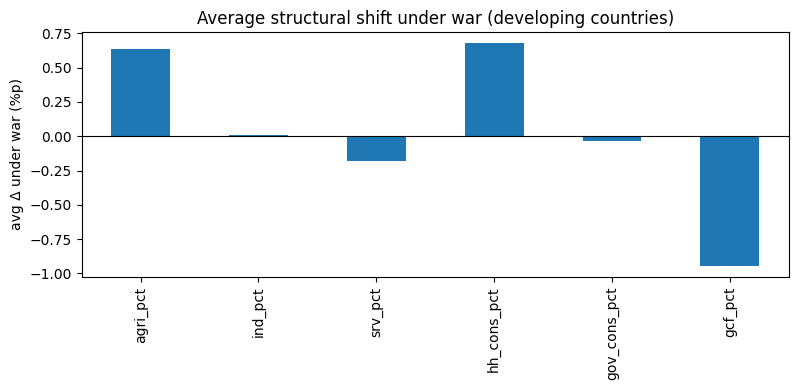

In [ ]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
# 실제 전쟁 발생 국가 중
# 상위 10% 수준의 전쟁 강도 설정
severe = m.loc[m['war_flag']==1, 'log_bdeaths'].quantile(0.9)
# 국가별 전쟁 충격 효과 저장용 리스트
rows = []
# 모든 개발도상국에 대해 반복 수행
for c, g in m.groupby('Country Code'):
    s = g.sort_values('year').iloc[-1]   # 국가별 가장 최근 연도 데이터 선택
    xr = s[feat].values.astype(float).reshape(1, -1)   # 모델 입력 형태로 변환
     # 평시 시나리오
    p = xr.copy(); p[0, feat.index('war_flag')]=0; p[0, feat.index('log_bdeaths')]=0
        # 분쟁 시나리오
    w = xr.copy(); w[0, feat.index('war_flag')]=1; w[0, feat.index('log_bdeaths')]=severe
        # 시나리오별 예측 수행
    dp = model.predict(scaler.transform(p), verbose=0).flatten()
    dw = model.predict(scaler.transform(w), verbose=0).flatten()
    # 전쟁 발생 시 변화량 계산
    # (분쟁 예측 - 평시 예측)

    rows.append(dw - dp)
# 국가별 결과를 데이터프레임으로 정리
diff = pd.DataFrame(rows, columns=struct)
# 구조별 평균 변화량 계산
print("전쟁 시 구조 변화 평균 (%p):"); print(diff.mean().round(3))
# 시각화
# 양수 → 전쟁 시 증가
# 음수 → 전쟁 시 감소

diff.mean().plot(kind='bar', figsize=(8,4))
plt.axhline(0, color='k', lw=0.8)
plt.ylabel('avg Δ under war (%p)')
plt.title('Average structural shift under war (developing countries)')
plt.tight_layout(); plt.show()

#회복력 데이터 구성 + 타깃 정의

In [ ]:
import numpy as np, pandas as pd
from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import StandardScaler

In [ ]:
import numpy as np, pandas as pd
from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import StandardScaler
import wbgapi as wb # Import wbgapi here as it's used


code = 'VC.BTL.DETH'
war_df = wb.data.DataFrame(code, economy='all', time=range(2000,2023),
                        columns='series', skipBlanks=False).reset_index()
war_df = war_df.rename(columns={'economy':'Country Code','time':'year_raw', code:'battle_deaths'})
war_df['year'] = war_df['year_raw'].astype(str).str.extract(r'(\d{4})').astype(int)

# panel + 전쟁 변수 결합 (Model 1과 동일한 베이스)
r = panel.merge(war_df[['Country Code', 'year', 'battle_deaths']],
                on=['Country Code', 'year'], how='left')
r['battle_deaths'] = r['battle_deaths'].fillna(0)

core = ['agri_pct', 'ind_pct', 'srv_pct', 'hh_cons_pct', 'gov_cons_pct',
        'gcf_pct', 'exp_pct', 'imp_pct', 'gdp_growth']
r = r.dropna(subset=core).sort_values(['Country Code', 'year']).copy()

# 충격·맥락 변수 (Model 1과 동일하게 가공)
r['war_flag']    = (r['battle_deaths'] > 0).astype(int)
r['log_bdeaths'] = np.log1p(r['battle_deaths'] / r['pop'] * 1e6)
r['log_ddeaths'] = np.log1p(r['dis_deaths']   / r['pop'] * 1e6)
r['log_pop']     = np.log1p(r['pop'])

# ── 회복 타깃: t 기준 '향후 3년 평균 GDP 성장률(%)' ──
# 같은 나라 안에서 t+1, t+2, t+3 성장률을 평균
g  = r.groupby('Country Code')['gdp_growth']
y_ = r.groupby('Country Code')['year']
g1, g2, g3 = g.shift(-1), g.shift(-2), g.shift(-3)
# t+1·t+2·t+3 이 실제로 연속된 해일 때만 사용 (중간에 빠진 해 배제)
ok = ((y_.shift(-1) - r['year'] == 1) &
      (y_.shift(-2) - r['year'] == 2) &
      (y_.shift(-3) - r['year'] == 3))
r['recovery3'] = (g1 + g2 + g3) / 3        # 향후 3년 평균 성장률(%)
r = r[ok].dropna(subset=['recovery3']).copy()

# 입력 X = Model 1과 같은 14개 / 출력 y = 회복력 1개
feat = ['agri_pct', 'ind_pct', 'srv_pct', 'hh_cons_pct', 'gov_cons_pct',
        'gcf_pct', 'exp_pct', 'imp_pct', 'log_pop', 'gdp_growth',
        'war_flag', 'log_bdeaths', 'disaster_flag', 'log_ddeaths']
Xr = r[feat].values
yr = r['recovery3'].values
print("회복력 데이터:", Xr.shape, "| 국가 수:", r['Country Code'].nunique())
print("회복력(향후3년 평균성장률) 분포:",
      f"평균 {yr.mean():.2f} / 중앙값 {np.median(yr):.2f} / 표준편차 {yr.std():.2f}")

# ── 분할: '국가 단위'로 나눠 같은 나라 누수 방지 (Model 1보다 엄격) ──
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
tr_idx, te_idx = next(gss.split(Xr, yr, groups=r['Country Code']))
Xr_tr, Xr_te = Xr[tr_idx], Xr[te_idx]
yr_tr, yr_te = yr[tr_idx], yr[te_idx]

sc_r = StandardScaler().fit(Xr_tr)              # train 기준 fit → 누수 방지
Xr_tr, Xr_te = sc_r.transform(Xr_tr), sc_r.transform(Xr_te)
print("train:", Xr_tr.shape, "| test:", Xr_te.shape)


회복력 데이터: (1984, 14) | 국가 수: 113
회복력(향후3년 평균성장률) 분포: 평균 3.93 / 중앙값 3.93 / 표준편차 3.49
train: (1564, 14) | test: (420, 14)


# 회복력 모델 구축 학습

In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

# 구조는 Model 1과 동일하게 두되, 출력만 1개(회복력)
rec_model = Sequential([
    Dense(64, activation='relu', input_shape=(Xr_tr.shape[1],)),
    Dropout(0.2),
    Dense(32, activation='relu'),
    Dropout(0.2),
    Dense(1)                       # 회복력 한 값 예측 (회귀)
])
rec_model.compile(optimizer='adam', loss='mse', metrics=['mae'])

es = EarlyStopping(monitor='val_loss', patience=30, restore_best_weights=True)
rec_hist = rec_model.fit(Xr_tr, yr_tr, validation_split=0.2,
                         epochs=500, batch_size=32, callbacks=[es], verbose=0)
print("학습 완료 (epoch:", len(rec_hist.history['loss']), ")")


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


학습 완료 (epoch: 48 )


# 평가 + baseline 비교

In [ ]:
from sklearn.metrics import r2_score, mean_absolute_error

yr_pred = rec_model.predict(Xr_te, verbose=0).flatten()
mae = mean_absolute_error(yr_te, yr_pred)
r2  = r2_score(yr_te, yr_pred)

# 비교 기준: 그냥 'train 평균'으로 전부 찍었을 때
base_pred = np.full_like(yr_te, yr_tr.mean())
base_r2   = r2_score(yr_te, base_pred)

print(f"[회복력 모델] MAE: {mae:.2f}%p | R²: {r2:.3f}")
print(f"[평균 예측 baseline] R²: {base_r2:.3f}")
print("→ 모델 R²가 baseline(≈0)보다 확실히 높으면 '회복을 어느 정도 설명한다'는 근거")
print("→ R²가 Model 1(0.9)보다 한참 낮은 건 정상: 회복 예측이 어렵다")

[회복력 모델] MAE: 2.76%p | R²: 0.036
[평균 예측 baseline] R²: -0.007
→ 모델 R²가 baseline(≈0)보다 확실히 높으면 '회복을 어느 정도 설명한다'는 근거
→ R²가 Model 1(0.9)보다 한참 낮은 건 정상: 회복 예측이 어렵다


\# 무엇이 회복을 가르나 — 변수 중요도 + 수출버퍼 검증

회복력 예측에서 중요한 변수 (클수록 중요):
      feature  importance
   gdp_growth      0.0478
      gcf_pct      0.0439
     agri_pct      0.0272
      srv_pct      0.0259
      exp_pct      0.0115
      imp_pct      0.0110
      log_pop      0.0068
  log_ddeaths      0.0031
  log_bdeaths      0.0029
disaster_flag      0.0025
 gov_cons_pct      0.0005
     war_flag     -0.0003
  hh_cons_pct     -0.0097
      ind_pct     -0.0345


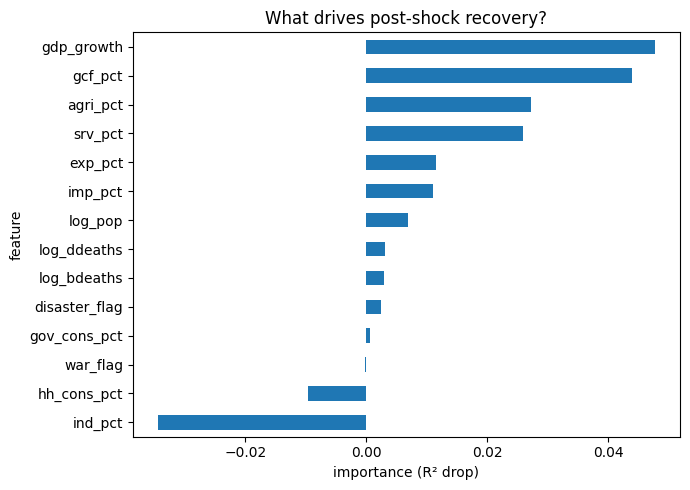


[충격 받은 국가-연도] 수출비중 상/하위별 실제 회복력:
               mean  median  count
export_tier                       
0_low_export   4.04    4.20    694
1_high_export  4.07    3.93    694


In [ ]:
import matplotlib.pyplot as plt

# (1) Permutation importance: 변수를 섞었을 때 R²가 얼마나 떨어지나
rng = np.random.default_rng(0)
base = r2_score(yr_te, rec_model.predict(Xr_te, verbose=0).flatten())
imp_rows = []
for j, name in enumerate(feat):
    drops = []
    Xp = Xr_te.copy()
    for _ in range(10):
        Xp[:, j] = rng.permutation(Xr_te[:, j])
        drops.append(base - r2_score(yr_te, rec_model.predict(Xp, verbose=0).flatten()))
        Xp[:, j] = Xr_te[:, j]
    imp_rows.append((name, np.mean(drops)))
imp_df = (pd.DataFrame(imp_rows, columns=['feature', 'importance'])
          .sort_values('importance', ascending=False))
print("회복력 예측에서 중요한 변수 (클수록 중요):")
print(imp_df.round(4).to_string(index=False))

imp_df.set_index('feature')['importance'].iloc[::-1].plot(
    kind='barh', figsize=(7, 5))
plt.xlabel('importance (R² drop)'); plt.title('What drives post-shock recovery?')
plt.tight_layout(); plt.show()

# (2) '석유 버퍼' 가설 직접 검증:
#     충격 받은 나라 중, 수출 비중 높은 그룹이 실제로 더 잘 회복했나?
shock = r[(r['war_flag'] == 1) | (r['disaster_flag'] == 1)].copy()
shock['export_tier'] = np.where(
    shock['exp_pct'] >= shock['exp_pct'].median(), '1_high_export', '0_low_export')
print("\n[충격 받은 국가-연도] 수출비중 상/하위별 실제 회복력:")
print(shock.groupby('export_tier')['recovery3']
      .agg(['mean', 'median', 'count']).round(2))

# 회복력 What-if — 수출비중을 올리면?


In [ ]:
print(sorted(r['Country Code'].unique()))

['AGO', 'ALB', 'ARG', 'ARM', 'AZE', 'BEN', 'BFA', 'BGD', 'BIH', 'BLR', 'BLZ', 'BOL', 'BRA', 'BTN', 'BWA', 'CAF', 'CHN', 'CIV', 'CMR', 'COD', 'COG', 'COL', 'COM', 'CPV', 'CUB', 'DJI', 'DOM', 'DZA', 'ECU', 'EGY', 'ETH', 'FJI', 'GAB', 'GEO', 'GHA', 'GIN', 'GMB', 'GNB', 'GNQ', 'GTM', 'HND', 'HTI', 'IDN', 'IND', 'IRN', 'IRQ', 'JOR', 'KAZ', 'KEN', 'KGZ', 'KHM', 'KIR', 'LAO', 'LBN', 'LBY', 'LKA', 'LSO', 'MAR', 'MDA', 'MDG', 'MDV', 'MEX', 'MHL', 'MKD', 'MLI', 'MNE', 'MNG', 'MOZ', 'MRT', 'MUS', 'MWI', 'MYS', 'NAM', 'NER', 'NIC', 'NPL', 'PAK', 'PER', 'PHL', 'PRY', 'PSE', 'RWA', 'SDN', 'SEN', 'SLB', 'SLE', 'SLV', 'SRB', 'STP', 'SUR', 'SWZ', 'TCD', 'TGO', 'THA', 'TJK', 'TKM', 'TLS', 'TON', 'TUN', 'TUR', 'TZA', 'UGA', 'UKR', 'UZB', 'VEN', 'VNM', 'VUT', 'WSM', 'XKX', 'YEM', 'ZAF', 'ZMB', 'ZWE']


In [ ]:
country = "LBN"   # 예시 국가 (원하는 ISO3로 변경)
if (r['Country Code'] == country).any():
    base_row = r[r['Country Code'] == country].sort_values('year').iloc[-1]
    x0 = base_row[feat].values.astype(float).reshape(1, -1)

    x_up = x0.copy()
    x_up[0, feat.index('exp_pct')] += 10      # 수출 비중 +10%p 가정

    p0 = rec_model.predict(sc_r.transform(x0), verbose=0).flatten()[0]
    p1 = rec_model.predict(sc_r.transform(x_up), verbose=0).flatten()[0]
    print(f"\n[{country}] 회복력 시나리오 (연관성 기반, 인과 아님)")
    print(f"  현재 수출비중 기준 예측 회복력 : {p0:.2f}%")
    print(f"  수출비중 +10%p 가정 시        : {p1:.2f}%  (차이 {p1-p0:+.2f}%p)")
else:
    print(f"\n{country} 는 표본에 없음 — r['Country Code'].unique() 에서 다른 나라 선택")


[LBN] 회복력 시나리오 (연관성 기반, 인과 아님)
  현재 수출비중 기준 예측 회복력 : 2.33%
  수출비중 +10%p 가정 시        : 2.38%  (차이 +0.05%p)


# 충격 표본 정의 + 실제 데이터로 직접 확인

In [ ]:
import numpy as np, pandas as pd

# 1) 충격 정의: 전쟁(전투사망>0) 또는 '심한' 재해(인구대비 재해사망 상위 10%)
r['deaths_pm'] = r['dis_deaths'] / r['pop'] * 1e6
dis_thr = r.loc[r['dis_deaths'] > 0, 'deaths_pm'].quantile(0.90)   # 재해해 중 상위 10%
r['severe_disaster'] = ((r['dis_deaths'] > 0) & (r['deaths_pm'] >= dis_thr)).astype(int)
r['shock'] = ((r['war_flag'] == 1) | (r['severe_disaster'] == 1)).astype(int)

shock = r[r['shock'] == 1].copy()
print(f"충격 표본: {len(shock)}행 / 전체 {len(r)}행 "
      f"({len(shock)/len(r)*100:.0f}%) | 국가 수: {shock['Country Code'].nunique()}")
print(f"  · 전쟁 {int((shock['war_flag']==1).sum())}행 / "
      f"심한재해 {int((shock['severe_disaster']==1).sum())}행")
print(f"  · 충격 표본 평균 회복력 {shock['recovery3'].mean():.2f}% "
      f"(전체 {r['recovery3'].mean():.2f}%)\n")

# 2) 핵심 검증: 충격받은 나라 중 '투자 높은 그룹'이 실제로 더 잘 회복했나?
#    (신경망이 아니라 실제 recovery3 비교 → 작은 표본에서도 안정적)
def tier_compare(df, var, label):
    med = df[var].median()
    hi = df.loc[df[var] >= med, 'recovery3']
    lo = df.loc[df[var] <  med, 'recovery3']
    print(f"  [{label:14s}] 상위 {hi.mean():.2f}% (n={len(hi)}) "
          f"vs 하위 {lo.mean():.2f}% (n={len(lo)})  →  차이 {hi.mean()-lo.mean():+.2f}%p")

print("충격받은 국가들에서 — 요인 상/하위 그룹별 '실제' 회복력:")
tier_compare(shock, 'gcf_pct',    '투자(gcf)')
tier_compare(shock, 'gdp_growth', '현재성장 모멘텀')
tier_compare(shock, 'exp_pct',    '수출비중')
tier_compare(shock, 'agri_pct',   '농업비중')

# 3) 상관계수 랭킹 (충격 표본 내) — 작은 표본에선 이게 '안정적 중요도'
print("\n충격 표본 내, 회복력과의 상관계수 (높을수록 회복에 +):")
corr = (shock[['gcf_pct','gdp_growth','exp_pct','agri_pct','ind_pct','srv_pct',
               'hh_cons_pct','gov_cons_pct']]
        .corrwith(shock['recovery3']).sort_values(ascending=False))
print(corr.round(3).to_string())


print(" · 투자(gcf) 상위그룹 차이가 (+)로 크고 상관도 상위면 → 투자가 회복을 가른다")
print(" · 차이가 0 근처거나 (-)면 → 전반적 성장에 영향을 미치지못했다.")



from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Input
from tensorflow.keras.callbacks import EarlyStopping

if shock['Country Code'].nunique() < 15 or len(shock) < 150:
    print("충격표본수가 부족합니다.")
else:
    Xs, ys = shock[feat].values, shock['recovery3'].values
    tr, te = next(GroupShuffleSplit(1, test_size=0.2, random_state=42)
                  .split(Xs, ys, groups=shock['Country Code']))
    Xs_tr, Xs_te, ys_tr, ys_te = Xs[tr], Xs[te], ys[tr], ys[te]
    sc_s = StandardScaler().fit(Xs_tr)
    Xs_tr, Xs_te = sc_s.transform(Xs_tr), sc_s.transform(Xs_te)

    ms = Sequential([Input(shape=(Xs_tr.shape[1],)),
                     Dense(64, activation='relu'), Dropout(0.2),
                     Dense(32, activation='relu'), Dropout(0.2), Dense(1)])
    ms.compile(optimizer='adam', loss='mse', metrics=['mae'])
    ms.fit(Xs_tr, ys_tr, validation_split=0.2, epochs=500, batch_size=32,
           callbacks=[EarlyStopping(monitor='val_loss', patience=30,
                                    restore_best_weights=True)], verbose=0)

    base = r2_score(ys_te, ms.predict(Xs_te, verbose=0).flatten())
    print(f"충격표본 NN — R²: {base:.3f} (test n={len(ys_te)})")

    rng = np.random.default_rng(0)
    rows = []
    for j, name in enumerate(feat):
        d, Xp = [], Xs_te.copy()
        for _ in range(10):
            Xp[:, j] = rng.permutation(Xs_te[:, j])
            d.append(base - r2_score(ys_te, ms.predict(Xp, verbose=0).flatten()))
            Xp[:, j] = Xs_te[:, j]
        rows.append((name, np.mean(d)))
    print("\n충격표본 변수 중요도 (참고용):")
    print(pd.DataFrame(rows, columns=['feature', 'importance'])
          .sort_values('importance', ascending=False).round(4).to_string(index=False))

충격 표본: 489행 / 전체 1984행 (25%) | 국가 수: 72
  · 전쟁 414행 / 심한재해 103행
  · 충격 표본 평균 회복력 4.15% (전체 3.93%)

충격받은 국가들에서 — 요인 상/하위 그룹별 '실제' 회복력:
  [투자(gcf)       ] 상위 4.64% (n=245) vs 하위 3.67% (n=244)  →  차이 +0.97%p
  [현재성장 모멘텀      ] 상위 4.93% (n=245) vs 하위 3.38% (n=244)  →  차이 +1.55%p
  [수출비중          ] 상위 4.16% (n=245) vs 하위 4.14% (n=244)  →  차이 +0.02%p
  [농업비중          ] 상위 4.58% (n=245) vs 하위 3.72% (n=244)  →  차이 +0.86%p

충격 표본 내, 회복력과의 상관계수 (높을수록 회복에 +):
gcf_pct         0.202
agri_pct        0.135
gdp_growth      0.073
hh_cons_pct     0.018
exp_pct        -0.001
gov_cons_pct   -0.021
srv_pct        -0.043
ind_pct        -0.066
 · 투자(gcf) 상위그룹 차이가 (+)로 크고 상관도 상위면 → 투자가 회복을 가른다
 · 차이가 0 근처거나 (-)면 → 전반적 성장에 영향을 미치지못했다.
충격표본 NN — R²: -0.113 (test n=105)

충격표본 변수 중요도 (참고용):
      feature  importance
      log_pop      0.0874
      gcf_pct      0.0840
      imp_pct      0.0339
  log_bdeaths      0.0132
disaster_flag      0.0094
  log_ddeaths      0.0082
     war_flag      0.0031
   gdp_growth     

# 요인별 상·하위 그룹의 실제 회복력 차이, 그리고 회복력과의 상관계수 랭킹

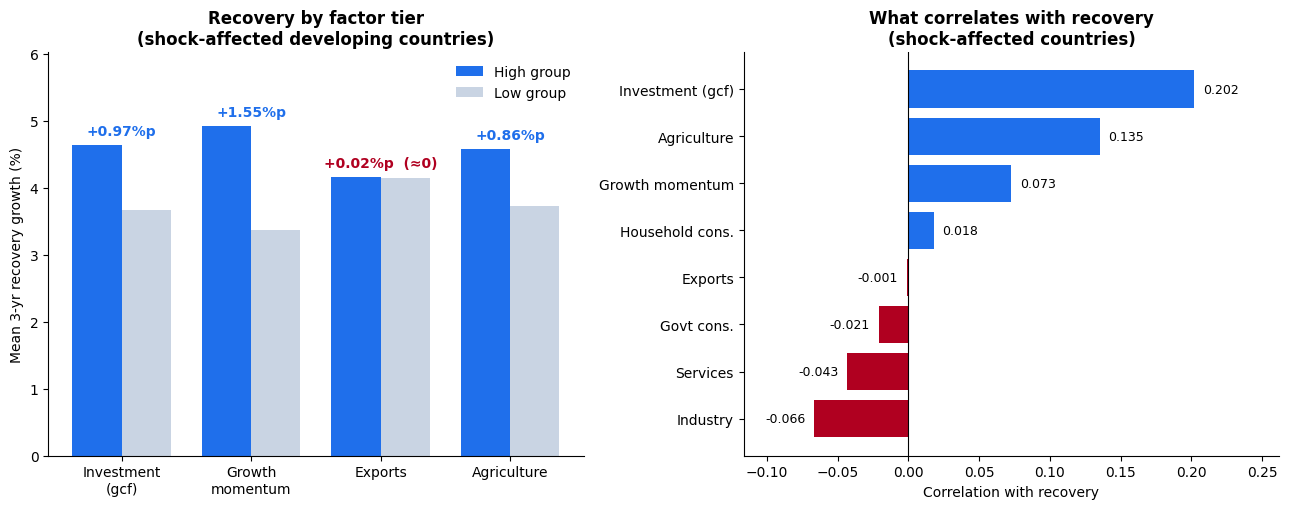

In [ ]:
# [회복 요인 시각화]  (shock 데이터프레임 사용)
import matplotlib.pyplot as plt
import numpy as np

# 1) 상/하위 그룹 회복력 (4개 요인) — shock에서 직접 계산
fac = [('gcf_pct','Investment\n(gcf)'), ('gdp_growth','Growth\nmomentum'),
       ('exp_pct','Exports'), ('agri_pct','Agriculture')]
labels, high, low, diff = [], [], [], []
for col, lab in fac:
    med = shock[col].median()
    h = shock.loc[shock[col] >= med, 'recovery3'].mean()
    l = shock.loc[shock[col] <  med, 'recovery3'].mean()
    labels.append(lab); high.append(h); low.append(l); diff.append(h-l)

# 2) 상관계수 (충격 표본 내)
order = ['gcf_pct','agri_pct','gdp_growth','hh_cons_pct','exp_pct',
         'gov_cons_pct','srv_pct','ind_pct']
nice = {'gcf_pct':'Investment (gcf)','agri_pct':'Agriculture','gdp_growth':'Growth momentum',
        'hh_cons_pct':'Household cons.','exp_pct':'Exports','gov_cons_pct':'Govt cons.',
        'srv_pct':'Services','ind_pct':'Industry'}
cvals = [shock[c].corr(shock['recovery3']) for c in order]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5.2))

# Panel 1: 상/하위 그룹 막대
x = np.arange(len(labels)); w = 0.38
ax1.bar(x - w/2, high, w, label='High group', color='#1f6feb')
ax1.bar(x + w/2, low,  w, label='Low group',  color='#c9d4e3')
for i, d in enumerate(diff):
    small = abs(d) < 0.2
    ax1.annotate(f'{d:+.2f}%p' + ('  (≈0)' if small else ''),
                 (x[i], max(high[i], low[i]) + 0.15), ha='center',
                 fontsize=10, fontweight='bold',
                 color='#b00020' if small else '#1f6feb')
ax1.set_xticks(x); ax1.set_xticklabels(labels, fontsize=10)
ax1.set_ylabel('Mean 3-yr recovery growth (%)')
ax1.set_title('Recovery by factor tier\n(shock-affected developing countries)',
              fontsize=12, fontweight='bold')
ax1.set_ylim(0, max(high)+1.1); ax1.legend(loc='upper right', frameon=False)
ax1.spines[['top','right']].set_visible(False)

# Panel 2: 상관계수
yb = np.arange(len(order))[::-1]
ax2.barh(yb, cvals, color=['#1f6feb' if v >= 0 else '#b00020' for v in cvals])
ax2.axvline(0, color='k', lw=0.8)
ax2.set_yticks(yb); ax2.set_yticklabels([nice[c] for c in order], fontsize=10)
ax2.set_xlabel('Correlation with recovery')
ax2.set_title('What correlates with recovery\n(shock-affected countries)',
              fontsize=12, fontweight='bold')
for v, y in zip(cvals, yb):
    ax2.annotate(f'{v:.3f}', (v + (0.006 if v >= 0 else -0.006), y),
                 va='center', ha='left' if v >= 0 else 'right', fontsize=9)
ax2.set_xlim(min(cvals)-0.05, max(cvals)+0.06)
ax2.spines[['top','right']].set_visible(False)

plt.tight_layout()
plt.savefig('recovery_factors.png', dpi=200, bbox_inches='tight')
plt.show()

# Part 3. 회복 실패 조기경보 + 완충 변수 (가설 H1·H2 검정)

[A] 분쟁 시작(onset) 사례 수 — 기준별
  전투사망    1명 이상: 시작 111건 / 56개국
  전투사망   25명 이상: 시작  87건 / 54개국
  전투사망 1000명 이상: 시작  39건 / 27개국
[B] 분석 표본
  충격 국가-연도 524행 / 74개국 (전쟁 448 · 심한재해 101)
  회복 실패율 0.193  (101건)
  완충 변수 결측률(채우기 전): {'remit': np.float64(0.126), 'oda': np.float64(0.0), 'infl_s': np.float64(0.032), 'mil': np.float64(0.078)}
[C] 회복 실패 예측 AUC (국가 단위 5-fold × 5회, 평균 ± 표준편차)
  Naive rule (growth only)     0.768 ± 0.000
  Logistic structure           0.743 ± 0.021
  MLP structure                0.495 ± 0.017
  Logistic structure+buffer    0.744 ± 0.025
  MLP structure+buffer         0.490 ± 0.011
[D] 표준화 로지스틱 계수 (+ = 실패 위험↑, 연관성이며 인과 아님)
gdp_growth     -1.234
log_pop        -0.655
remit          -0.445
exp_pct        -0.354
log_ddeaths    -0.239
oda            -0.174
log_bdeaths    -0.155
gcf_pct        -0.121
infl_s         -0.014
gov_cons_pct   -0.005
war_flag        0.015
imp_pct         0.032
hh_cons_pct     0.168
srv_pct         0.260
mil             0.330
agri_pct        0.713
ind_p

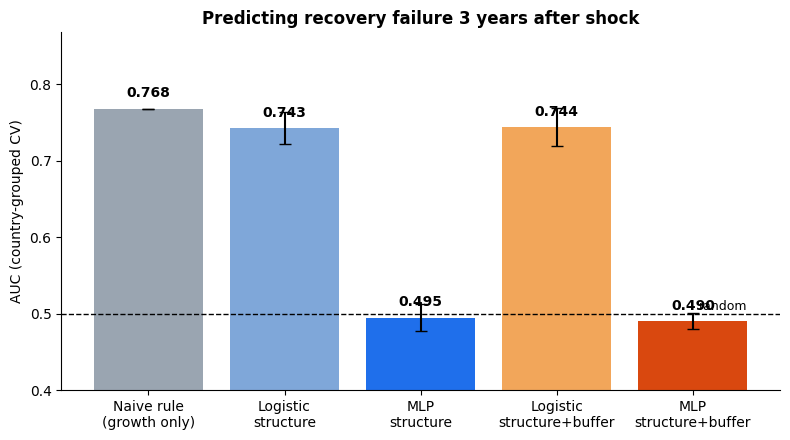

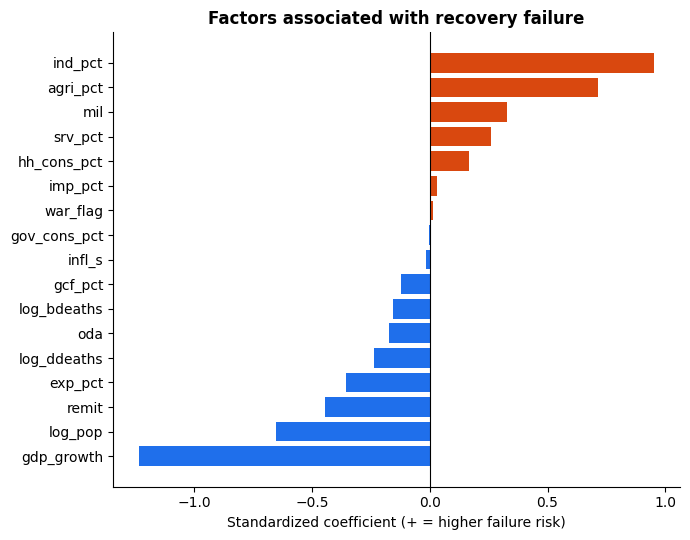

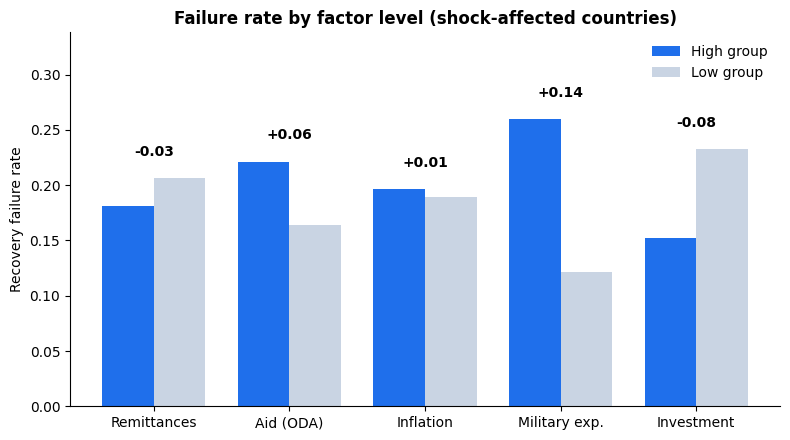

그림 저장 완료: fig1_auc.png, fig2_coef.png, fig3_tiers.png


In [ ]:
# ================================================================
# [포스터용] 충격 후 '회복 실패' 조기경보 + 완충 변수 효과
# 실행 전제: 기존 노트북 셀 1~13을 먼저 실행해서 `panel`이 있어야 함
# ================================================================
import numpy as np, pandas as pd, matplotlib.pyplot as plt, warnings
import wbgapi as wb
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import roc_auc_score
warnings.filterwarnings('ignore')

# ---------- 1) 추가 지표 수집: 전투사망 + 1인당GDP + 완충 변수 ----------
extra = {
    'VC.BTL.DETH':         'battle_deaths',  # 전투 사망자
    'NY.GDP.PCAP.KD':      'gdppc',          # 1인당 GDP (불변가격)
    'BX.TRF.PWKR.DT.GD.ZS':'remit',          # 해외송금 유입 (% GDP)
    'DT.ODA.ODAT.GN.ZS':   'oda',            # 순 공적개발원조 (% GNI)
    'FP.CPI.TOTL.ZG':      'infl',           # 인플레이션 (연 %)
    'MS.MIL.XPND.GD.ZS':   'mil',            # 군사비 (% GDP)
}
ex = wb.data.DataFrame(list(extra), economy='all', time=range(1998, 2024),
                       columns='series', skipBlanks=False).reset_index()
ex = ex.rename(columns={'economy': 'Country Code', 'time': 'yr', **extra})
ex['year'] = ex['yr'].astype(str).str.extract(r'(\d{4})').astype(int)
ex = ex.drop(columns='yr')

# 1인당 GDP는 t-1 ~ t+3이 필요하므로 panel 범위 밖 연도도 사용
g = ex[['Country Code', 'year', 'gdppc']].copy()
d = panel.merge(ex, on=['Country Code', 'year'], how='left')
d['battle_deaths'] = d['battle_deaths'].fillna(0)
d = d.sort_values(['Country Code', 'year']).reset_index(drop=True)

# ---------- 2) 분쟁 시작(onset) 사례 수 확인 ----------
print("=" * 60); print("[A] 분쟁 시작(onset) 사례 수 — 기준별")
for th in [1, 25, 1000]:
    w = (d['battle_deaths'] >= th).astype(int)
    on = (w == 1) & (w.groupby(d['Country Code']).shift(1) == 0)
    print(f"  전투사망 {th:>4}명 이상: 시작 {int(on.sum()):>3}건 / {d.loc[on, 'Country Code'].nunique()}개국")

# ---------- 3) 충격 정의: 전쟁 또는 심한 재해 ----------
d['war_flag'] = (d['battle_deaths'] > 0).astype(int)
d['deaths_pm'] = d['dis_deaths'] / d['pop'] * 1e6
thr = d.loc[d['dis_deaths'] > 0, 'deaths_pm'].quantile(0.90)
d['severe_dis'] = ((d['dis_deaths'] > 0) & (d['deaths_pm'] >= thr)).astype(int)
d['shock'] = ((d['war_flag'] == 1) | (d['severe_dis'] == 1)).astype(int)

# ---------- 4) 타깃: 3년 뒤 1인당 GDP가 충격 직전(t-1) 수준 미만이면 '회복 실패' ----------
gi = g.set_index(['Country Code', 'year'])['gdppc']
def gp(row, k):
    return gi.get((row['Country Code'], row['year'] + k), np.nan)
d['gdppc_pre']  = d.apply(lambda r: gp(r, -1), axis=1)
d['gdppc_post'] = d.apply(lambda r: gp(r, 3), axis=1)
s = d[(d['shock'] == 1)].dropna(subset=['gdppc_pre', 'gdppc_post']).copy()
s['fail'] = (s['gdppc_post'] < s['gdppc_pre']).astype(int)

# ---------- 5) 특징: 구조 변수(기존) vs 구조 + 완충 변수 ----------
s['log_pop']     = np.log1p(s['pop'])
s['log_bdeaths'] = np.log1p(s['battle_deaths'] / s['pop'] * 1e6)
s['log_ddeaths'] = np.log1p(s['dis_deaths'] / s['pop'] * 1e6)
s['infl_s']      = np.sign(s['infl']) * np.log1p(s['infl'].abs())   # 초인플레 완화
struct_f = ['agri_pct', 'ind_pct', 'srv_pct', 'hh_cons_pct', 'gov_cons_pct', 'gcf_pct',
            'exp_pct', 'imp_pct', 'log_pop', 'gdp_growth', 'war_flag', 'log_bdeaths', 'log_ddeaths']
buffer_f = ['remit', 'oda', 'infl_s', 'mil']
s = s.dropna(subset=struct_f).copy()
miss = s[buffer_f].isna().mean().round(3)
# 완충 변수 결측: 같은 나라 다른 해 값 → 전체 중앙값 순으로 채움 (결측률은 한계에 명시)
for c in buffer_f:
    s[c] = s.groupby('Country Code')[c].transform(lambda x: x.fillna(x.median()))
    s[c] = s[c].fillna(s[c].median())

y, grp = s['fail'].values, s['Country Code'].values
print("=" * 60); print("[B] 분석 표본")
print(f"  충격 국가-연도 {len(s)}행 / {s['Country Code'].nunique()}개국 "
      f"(전쟁 {int(s['war_flag'].sum())} · 심한재해 {int(s['severe_dis'].sum())})")
print(f"  회복 실패율 {y.mean():.3f}  ({int(y.sum())}건)")
print("  완충 변수 결측률(채우기 전):", dict(miss))

# ---------- 6) 국가 단위 교차검증 (같은 나라가 train/test에 동시에 안 들어감) ----------
def oof_auc(cols, model_fn, seeds=range(5)):
    aucs = []
    for sd in seeds:
        cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=sd)
        p = np.zeros(len(y))
        for tr, te in cv.split(s, y, grp):
            m = model_fn(); m.fit(s.iloc[tr][cols].values, y[tr])
            p[te] = m.predict_proba(s.iloc[te][cols].values)[:, 1]
        aucs.append(roc_auc_score(y, p))
    return np.mean(aucs), np.std(aucs)

logit = lambda: make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, C=0.5))
mlp   = lambda: make_pipeline(StandardScaler(), MLPClassifier(
            hidden_layer_sizes=(32, 16), alpha=1e-2, early_stopping=True,
            max_iter=2000, random_state=0))

naive = roc_auc_score(y, -s['gdp_growth'])   # "올해 성장률 낮으면 실패" 단순 규칙
res = {'Naive rule\n(growth only)': (naive, 0.0)}
res['Logistic\nstructure']          = oof_auc(struct_f, logit)
res['MLP\nstructure']               = oof_auc(struct_f, mlp)
res['Logistic\nstructure+buffer']   = oof_auc(struct_f + buffer_f, logit)
res['MLP\nstructure+buffer']        = oof_auc(struct_f + buffer_f, mlp)
print("=" * 60); print("[C] 회복 실패 예측 AUC (국가 단위 5-fold × 5회, 평균 ± 표준편차)")
for k, (a, sd) in res.items():
    print(f"  {k.replace(chr(10), ' '):28s} {a:.3f} ± {sd:.3f}")

# ---------- 7) 해석: 표준화 로지스틱 계수 (+면 실패 위험 증가) ----------
lm = logit().fit(s[struct_f + buffer_f].values, y)
coef = pd.Series(lm[-1].coef_[0], index=struct_f + buffer_f).sort_values()
print("=" * 60); print("[D] 표준화 로지스틱 계수 (+ = 실패 위험↑, 연관성이며 인과 아님)")
print(coef.round(3).to_string())

# ---------- 8) 완충 변수 상/하위 그룹별 실제 실패율 ----------
print("=" * 60); print("[E] 요인 상/하위(중앙값 기준) 그룹별 실제 회복 실패율")
tiers = []
for c, lab in [('remit', 'Remittances'), ('oda', 'Aid (ODA)'), ('infl_s', 'Inflation'),
               ('mil', 'Military exp.'), ('gcf_pct', 'Investment')]:
    hi = s[c] >= s[c].median()
    fh, fl = y[hi.values].mean(), y[~hi.values].mean()
    tiers.append((lab, fh, fl))
    print(f"  {lab:14s} 상위 {fh:.3f} (n={hi.sum()}) vs 하위 {fl:.3f} (n={(~hi).sum()}) → 차이 {fh-fl:+.3f}")

# ---------- 9) 포스터용 그림 3장 ----------
names = list(res); vals = [res[k][0] for k in names]; errs = [res[k][1] for k in names]
plt.figure(figsize=(8, 4.5))
plt.bar(names, vals, yerr=errs, capsize=4,
        color=['#9aa5b1', '#7fa7d9', '#1f6feb', '#f2a65a', '#d9480f'])
plt.axhline(0.5, color='k', ls='--', lw=1); plt.text(4.4, 0.505, 'random', ha='right', fontsize=9)
for i, v in enumerate(vals): plt.text(i, v + 0.015, f'{v:.3f}', ha='center', fontsize=10, fontweight='bold')
plt.ylim(0.4, max(vals) + 0.1); plt.ylabel('AUC (country-grouped CV)')
plt.title('Predicting recovery failure 3 years after shock', fontweight='bold')
plt.gca().spines[['top', 'right']].set_visible(False); plt.tight_layout()
plt.savefig('fig1_auc.png', dpi=250); plt.show()

plt.figure(figsize=(7, 5.5))
plt.barh(coef.index, coef.values, color=['#1f6feb' if v < 0 else '#d9480f' for v in coef.values])
plt.axvline(0, color='k', lw=0.8); plt.xlabel('Standardized coefficient (+ = higher failure risk)')
plt.title('Factors associated with recovery failure', fontweight='bold')
plt.gca().spines[['top', 'right']].set_visible(False); plt.tight_layout()
plt.savefig('fig2_coef.png', dpi=250); plt.show()

lab = [t[0] for t in tiers]; x = np.arange(len(lab)); w = 0.38
plt.figure(figsize=(8, 4.5))
plt.bar(x - w/2, [t[1] for t in tiers], w, label='High group', color='#1f6feb')
plt.bar(x + w/2, [t[2] for t in tiers], w, label='Low group', color='#c9d4e3')
for i, t in enumerate(tiers):
    plt.text(i, max(t[1], t[2]) + 0.02, f'{t[1]-t[2]:+.2f}', ha='center', fontweight='bold')
plt.xticks(x, lab); plt.ylabel('Recovery failure rate'); plt.legend(frameon=False)
plt.ylim(0, max(max(t[1], t[2]) for t in tiers) * 1.3)
plt.title('Failure rate by factor level (shock-affected countries)', fontweight='bold')
plt.gca().spines[['top', 'right']].set_visible(False); plt.tight_layout()
plt.savefig('fig3_tiers.png', dpi=250); plt.show()

print("=" * 60); print("그림 저장 완료: fig1_auc.png, fig2_coef.png, fig3_tiers.png")


# Part 4. 후퇴 연수: 전쟁은 경제를 몇 년 전으로 되돌리나

[F] 분쟁 발발 사례 (전투사망 1000명↑): 35건 / 24개국
  1인당 GDP 최대 하락률  중앙값 -1.4% | 하위25% -11.0%
  후퇴 연수            중앙값 1년 | 상위25% 6년 | 하락 없음(0년) 43%
country  onset  loss_pct  years_back  censored
    LBY   2019     -39.1          55     False
    LBY   2011     -49.1          47     False
    SYR   2011     -44.5          37     False
    YEM   2014     -45.2          23      True
    YEM   2011     -17.2          14     False
    SDN   2015      -9.3          12     False
    AZE   2020      -4.9          11     False
    UKR   2014     -13.9           9     False
    IRQ   2003     -38.5           6     False
    MMR   2021     -12.6           6     False

  우크라이나 2022: 2021=100 기준 77.3 → 2003년 수준 (18년 후퇴) | 35건 사이에 놓으면 5번째


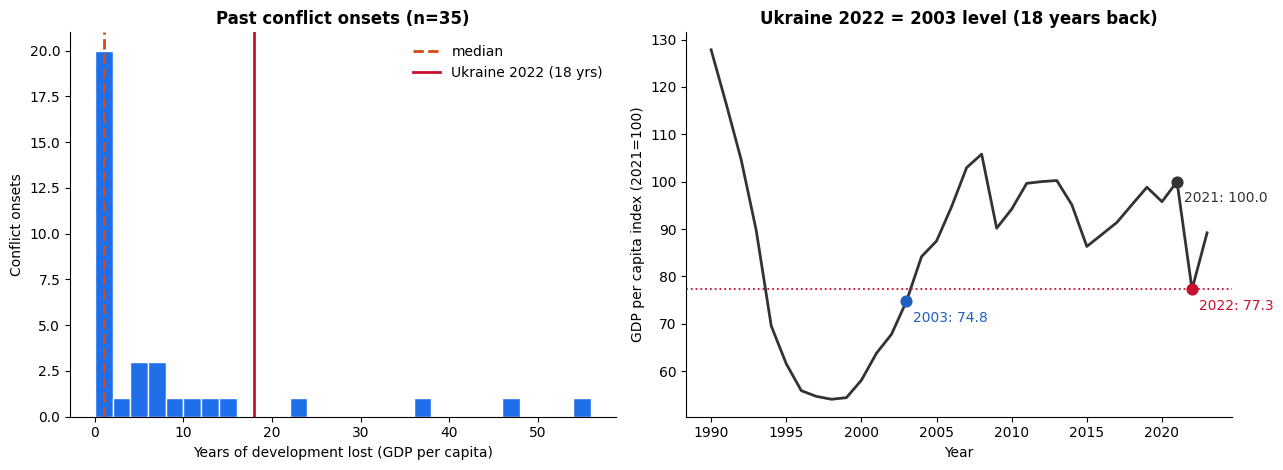

In [ ]:
# ================================================================
# [F] 전쟁은 경제를 몇 년 전으로 되돌리나 — 후퇴 연수
# 정의: 분쟁 발발(t) 후 t~t+3년 1인당 실질 GDP 최저점이
#       '마지막으로 그 이하였던 해'로부터 몇 년 전인지 (모델 예측 아님, 관측값)
# ================================================================
import numpy as np, pandas as pd, matplotlib.pyplot as plt, wbgapi as wb

gl = wb.data.DataFrame(['NY.GDP.PCAP.KD'], economy='all', time=range(1960, 2024),
                       columns='series', skipBlanks=False).reset_index()
gl['year'] = gl['time'].astype(str).str.extract(r'(\d{4})').astype(int)
G = gl.pivot_table(index='economy', columns='year', values='NY.GDP.PCAP.KD')

def years_back(c, level, before):
    """before 이하 연도 중 1인당 GDP가 level 이하였던 마지막 해 → (그 해, 후퇴 연수, 하한값 여부)"""
    s_ = G.loc[c, :before].dropna()
    hit = s_[s_ <= level]
    if len(hit) == 0:
        return int(s_.index.min()), before - int(s_.index.min()), True
    return int(hit.index.max()), before - int(hit.index.max()), False

def setback_events(TH):
    """전투사망 TH명 이상 분쟁의 발발 사례별 후퇴 연수"""
    w = (d['battle_deaths'] >= TH).astype(int)
    on = d[(w == 1) & (w.groupby(d['Country Code']).shift(1) == 0)]
    rows = []
    for _, r_ in on.iterrows():
        c, t = r_['Country Code'], int(r_['year'])
        if c not in G.index or pd.isna(G.loc[c].get(t - 1)): continue
        post = G.loc[c, t:t + 3].dropna()
        if len(post) < 3: continue                         # 발발 후 3년 관측 필요
        pre = G.loc[c, t - 1]; trough = min(post.min(), pre)
        yr, back, cens = years_back(c, trough, t - 1)
        rows.append(dict(country=c, onset=t, loss_pct=(trough / pre - 1) * 100,
                         years_back=back, censored=cens))
    return pd.DataFrame(rows)

TH = 1000
ev = setback_events(TH)
print("=" * 60); print(f"[F] 분쟁 발발 사례 (전투사망 {TH}명↑): {len(ev)}건 / {ev['country'].nunique()}개국")
print(f"  1인당 GDP 최대 하락률  중앙값 {ev['loss_pct'].median():.1f}% | 하위25% {ev['loss_pct'].quantile(.25):.1f}%")
print(f"  후퇴 연수            중앙값 {ev['years_back'].median():.0f}년 | 상위25% {ev['years_back'].quantile(.75):.0f}년"
      f" | 하락 없음(0년) {(ev['years_back']==0).mean()*100:.0f}%")
print(ev.sort_values('years_back', ascending=False).head(10).round(1).to_string(index=False))

# 우크라이나 2022: 발발 후 3년 관측이 없어 위 표본에는 없음 → 같은 정의로 별도 계산
u = G.loc['UKR'].dropna()
u_yr, u_back, _ = years_back('UKR', u[2022], 2021)
rank = int((ev['years_back'] > u_back).sum()) + 1
print(f"\n  우크라이나 2022: 2021=100 기준 {u[2022]/u[2021]*100:.1f} → {u_yr}년 수준 ({u_back}년 후퇴)"
      f" | {len(ev)}건 사이에 놓으면 {rank}번째")

fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4.8))
a1.hist(ev['years_back'], bins=range(0, int(ev['years_back'].max()) + 3, 2),
        color='#1f6feb', edgecolor='white')
a1.axvline(ev['years_back'].median(), color='#d9480f', ls='--', lw=2, label='median')
a1.axvline(u_back, color='#c8102e', lw=2, label=f'Ukraine 2022 ({u_back} yrs)')
a1.set_xlabel('Years of development lost (GDP per capita)'); a1.set_ylabel('Conflict onsets')
a1.set_title(f'Past conflict onsets (n={len(ev)})', fontweight='bold'); a1.legend(frameon=False)
idx = u.loc[1990:] / u[2021] * 100
a2.plot(idx.index, idx.values, color='#333', lw=2)
a2.axhline(idx[2022], color='#c8102e', ls=':', lw=1.3)
for yy, col in [(2021, '#333'), (2022, '#c8102e'), (u_yr, '#1f5fbf')]:
    a2.scatter([yy], [idx[yy]], color=col, s=60, zorder=3)
    a2.annotate(f'{yy}: {idx[yy]:.1f}', (yy, idx[yy]), (5, -15), textcoords='offset points', color=col)
a2.set_xlabel('Year'); a2.set_ylabel('GDP per capita index (2021=100)')
a2.set_title(f'Ukraine 2022 = {u_yr} level ({u_back} years back)', fontweight='bold')
for a in (a1, a2): a.spines[['top', 'right']].set_visible(False)
plt.tight_layout(); plt.savefig('fig4_setback.png', dpi=250); plt.show()


### 우크라이나: 1인당 vs 총량

In [ ]:
# [H] 우크라이나 실제 관측: 1인당 vs 총량 (영토 변화·인구 유출 효과 확인)
gt = wb.data.DataFrame(['NY.GDP.MKTP.KD'], economy='all', time=range(1960, 2024),
                       columns='series', skipBlanks=False).reset_index()
gt['year'] = gt['time'].astype(str).str.extract(r'(\d{4})').astype(int)
T = gt.pivot_table(index='economy', columns='year', values='NY.GDP.MKTP.KD')

def last_below(ser, level, before):
    h = ser[(ser.index <= before) & (ser <= level)]
    return (int(h.index.max()), before - int(h.index.max())) if len(h) else (None, None)

print("=" * 60); print("[H] 우크라이나 (2021 = 100)")
for name, M in [('1인당 실질GDP', G), ('실질GDP 총량', T)]:
    us = M.loc['UKR'].dropna()
    yr, back = last_below(us, us[2022], 2021)
    print(f"  {name}: 2022 = {us[2022]/us[2021]*100:.1f} → 마지막으로 이보다 낮았던 해 {yr} ({back}년 전)")
    print("   ", (us.loc[1990:] / us[2021] * 100).round(1).to_dict())


[H] 우크라이나 (2021 = 100)
  1인당 실질GDP: 2022 = 77.3 → 마지막으로 이보다 낮았던 해 2003 (18년 전)
    {1990: 127.8, 1991: 116.5, 1992: 104.6, 1993: 89.7, 1994: 69.5, 1995: 61.5, 1996: 55.9, 1997: 54.7, 1998: 54.1, 1999: 54.4, 2000: 58.1, 2001: 63.8, 2002: 67.8, 2003: 74.8, 2004: 84.2, 2005: 87.5, 2006: 94.7, 2007: 103.0, 2008: 105.8, 2009: 90.2, 2010: 94.2, 2011: 99.7, 2012: 100.0, 2013: 100.2, 2014: 95.1, 2015: 86.3, 2016: 88.9, 2017: 91.4, 2018: 95.1, 2019: 98.8, 2020: 95.8, 2021: 100.0, 2022: 77.3, 2023: 89.2}
  실질GDP 총량: 2022 = 71.2 → 마지막으로 이보다 낮았던 해 2000 (21년 전)
    {1990: 159.1, 1991: 145.3, 1992: 130.9, 1993: 112.3, 1994: 86.6, 1995: 76.0, 1996: 68.4, 1997: 66.4, 1998: 65.1, 1999: 65.0, 2000: 68.8, 2001: 74.9, 2002: 78.9, 2003: 86.4, 2004: 96.5, 2005: 99.5, 2006: 107.0, 2007: 115.8, 2008: 118.4, 2009: 100.5, 2010: 104.6, 2011: 110.3, 2012: 110.5, 2013: 110.5, 2014: 99.4, 2015: 89.7, 2016: 91.9, 2017: 94.0, 2018: 97.3, 2019: 100.4, 2020: 96.7, 2021: 100.0, 2022: 71.2, 2023: 75.2}


# Part 5. 강건성 검증

In [ ]:
# ================================================================
# [I] 강건성 검증 — 포스터의 주장이 분석 선택에 따라 뒤집히지 않는가
# ================================================================
import numpy as np, pandas as pd
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

# (1) 후퇴 연수: 분쟁 기준(전투사망 25명↑ vs 1000명↑)을 바꿔도 "대부분 작고 꼬리가 길다"가 유지되나
print("=" * 60); print("[I-1] 분쟁 기준별 후퇴 연수 분포")
for th in [25, 1000]:
    e = setback_events(th)
    print(f"  {th:>4}명↑: {len(e):>3}건 | 중앙값 {e['years_back'].median():.0f}년 | "
          f"0년 {(e['years_back']==0).mean()*100:.0f}% | 상위25% {e['years_back'].quantile(.75):.0f}년 | "
          f"최대 {e['years_back'].max():.0f}년")

# (2) 그룹 차이의 95% 신뢰구간 — '국가' 단위로 다시 뽑는 부트스트랩
#     같은 나라가 여러 해 반복 관측되므로 행 단위가 아니라 국가 단위로 재표집해야 정직함
print("=" * 60); print("[I-2] 상위-하위 그룹 실패율 차이, 국가 단위 부트스트랩 95% CI (1000회)")
rng = np.random.default_rng(42)
countries = s['Country Code'].unique()
by_c = {c: s[s['Country Code'] == c] for c in countries}
for col, lab in [('mil', '군사비'), ('gcf_pct', '투자'), ('oda', '원조'), ('remit', '송금')]:
    med = s[col].median()
    def diff(df):
        hi = df[df[col] >= med]['fail']; lo = df[df[col] < med]['fail']
        return hi.mean() - lo.mean() if len(hi) and len(lo) else np.nan
    obs = diff(s)
    boots = [diff(pd.concat([by_c[c] for c in rng.choice(countries, len(countries))]))
             for _ in range(1000)]
    lo_, hi_ = np.nanpercentile(boots, [2.5, 97.5])
    sig = '0 미포함 → 차이 유지' if (lo_ > 0 or hi_ < 0) else '0 포함 → 우연과 구분 불가'
    print(f"  {lab:4s} {obs*100:+6.1f}%p  [{lo_*100:+.1f}, {hi_*100:+.1f}]  {sig}")

# (3) MLP 붕괴가 '모델 한계'인지 '설정 문제'인지: early stopping 끄고 규제 강화
print("=" * 60); print("[I-3] MLP 재설정 (early stopping 해제, 작은 망, 강한 L2 규제)")
mlp2 = lambda: make_pipeline(StandardScaler(), MLPClassifier(
    hidden_layer_sizes=(16,), alpha=1.0, early_stopping=False, max_iter=800, random_state=0))
for nm, cols in [('구조변수', struct_f), ('구조+완충', struct_f + buffer_f)]:
    a, sd = oof_auc(cols, mlp2)
    print(f"  MLP(재설정) {nm:6s} AUC {a:.3f} ± {sd:.3f}   (기존 설정 {res['MLP' + chr(10) + ('structure' if nm=='구조변수' else 'structure+buffer')][0]:.3f},"
          f" 단순 규칙 {naive:.3f})")


[I-1] 분쟁 기준별 후퇴 연수 분포
    25명↑:  80건 | 중앙값 0년 | 0년 52% | 상위25% 4년 | 최대 47년
  1000명↑:  35건 | 중앙값 1년 | 0년 43% | 상위25% 6년 | 최대 55년
[I-2] 상위-하위 그룹 실패율 차이, 국가 단위 부트스트랩 95% CI (1000회)
  군사비   +13.9%p  [+2.5, +26.7]  0 미포함 → 차이 유지
  투자     -8.0%p  [-19.0, +3.0]  0 포함 → 우연과 구분 불가
  원조     +5.7%p  [-8.0, +18.4]  0 포함 → 우연과 구분 불가
  송금     -2.6%p  [-14.7, +9.9]  0 포함 → 우연과 구분 불가
[I-3] MLP 재설정 (early stopping 해제, 작은 망, 강한 L2 규제)
  MLP(재설정) 구조변수   AUC 0.692 ± 0.022   (기존 설정 0.495, 단순 규칙 0.768)
  MLP(재설정) 구조+완충  AUC 0.668 ± 0.034   (기존 설정 0.490, 단순 규칙 0.768)


# 그림 다운로드

In [ ]:
# 포스터용 그림 한 번에 다운로드
import zipfile
from google.colab import files
with zipfile.ZipFile('poster_figs.zip', 'w') as z:
    for f in ['fig1_auc.png', 'fig2_coef.png', 'fig3_tiers.png', 'fig4_setback.png']:
        z.write(f)
files.download('poster_figs.zip')


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [43]:
import json
from google.colab import files
names = wb.economy.DataFrame(skipAggs=True)['name']
out = {'onsets': ev[['country','onset','years_back','loss_pct']].round(1).to_dict('records'), 'countries': {}}
for c in names.index:
    if c in G.index and G.loc[c].notna().sum() > 10:
        pc = G.loc[c].dropna().round(1); tt = T.loc[c].dropna() if c in T.index else pc.iloc[:0]
        out['countries'][c] = {'name': names[c], 'pc': {int(k): float(v) for k, v in pc.items()},
                               'tot': {int(k): round(float(v)/1e6, 1) for k, v in tt.items()}}
json.dump(out, open('setback_data.json', 'w'), ensure_ascii=False); files.download('setback_data.json')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>